# Clean Velocity Data

This notebook is used to clean velocity profiles with common site or metadata coordinates.

# Load Packages

In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import os
import math
import matplotlib.colors as mcolors
import networkx as nx
from scipy.spatial import distance_matrix
from pyproj import Proj, transform
from mpl_toolkits.mplot3d import Axes3D
import geopandas as gpd

#get UTM zone 
def longlat_to_utm(lon, lat):
    utm_zone = int((lon + 180) / 6) + 1
    proj = Proj(proj='utm', zone=utm_zone, ellps='WGS84')
    easting, northing = proj(lon, lat)
    return easting, northing

### Define Variables

In [5]:
# file names raw data
fn_sites_LA    = '../Data/Raw_data/sites_LA_basin.csv'
fn_metadata    = '../Data/Raw_data/velocity_metadata.csv'
fn_tests       = '../Data/Raw_data/tests.csv'
fn_vs_points   = '../Data/Raw_data/vs_point_data.csv'
fn_vs_layers   = '../Data/Raw_data/vs_layer_data.csv'

#data directory
dir_out = '../Data/Vel_data/Preprocessing_borehole/'
dir_fig = '../Data/Figure/'

### Load Datasets

In [6]:
#site info
df_sites_LA = pd.read_csv(fn_sites_LA)
df_sites_LA.rename(columns={'id':'site_id'}, inplace=True)

#metadata info
df_metadata = pd.read_csv(fn_metadata)
df_metadata.rename(columns={'id':'metadata_id'}, inplace=True)

#test info
df_tests = pd.read_csv(fn_tests)
df_tests.rename(columns={'id':'test_id'}, inplace=True)

#vs points and layers info
df_vs_points = pd.read_csv(fn_vs_points, index_col=0)
df_vs_layers = pd.read_csv(fn_vs_layers, index_col=0)

### Merge Metadata

In [7]:
#remove sites and tests with invalid coordinates
i_inval_sites = (np.abs(df_sites_LA.site_longitude) > 180).values
i_inval_tests = (np.abs(df_tests.test_longitude) > 180).values
print("Number of invalid sites: ", np.sum(i_inval_sites))
print("Number of invalid tests: ", np.sum(i_inval_tests))
df_sites_LA = df_sites_LA[~i_inval_sites]
df_tests    = df_tests[~i_inval_tests]

#merge test and site info
df_sites = pd.merge(df_tests, df_sites_LA, on='site_id', how='inner')
#merge metadata info
df_sites = pd.merge(df_metadata, df_sites, on='test_id',  how='inner')

#identify sites with duplicate tests
tests, idx, counts = np.unique(df_sites.test_id, return_index=True, return_counts=True)
print("Douplicate tests:")
print(tests[counts>1])
print("Douplicate tests:")
print(df_sites.site_id.values[idx[counts>1]])

# #remove duplicate test ids
# df_sites = df_sites.iloc[idx,:]

#comptue site UTM coordinates
df_sites[['site_easting', 'site_northing']] = df_sites.apply(lambda row: pd.Series(longlat_to_utm(row['site_longitude'], 
                                                                                                  row['site_latitude'])),
                                                             axis=1)
#comptue test UTM coordinates
df_sites[['test_easting', 'test_northing']] = df_sites.apply(lambda row: pd.Series(longlat_to_utm(row['test_longitude'], 
                                                                                                  row['test_latitude'])),
                                                             axis=1)                                                      

Number of invalid sites:  0
Number of invalid tests:  2
Douplicate tests:
[ 320  332  397  407  498  499  500  501  502 1278]
Douplicate tests:
[ 314  325  381  390  465  465  465  465  465 3154]


#### Identify Duplicate Sites

In [8]:
#compute site distances
dist_mat_sites = distance_matrix(df_sites[['site_easting', 'site_northing']], 
                                 df_sites[['site_easting', 'site_northing']])
np.fill_diagonal(dist_mat_sites, np.inf)

#compute test distances
dist_mat_tests = distance_matrix(df_sites[['test_easting', 'test_northing']], 
                                 df_sites[['test_easting', 'test_northing']])
np.fill_diagonal(dist_mat_tests, np.inf)

#identify colocated sites
sites_zero_dist = np.argwhere(dist_mat_sites == 0.0)
sites_zero_dist = [tuple(pair) for pair in sites_zero_dist if pair[0] < pair[1]]
#create a graph with zero-distance sites
sites_G = nx.Graph()
sites_G.add_edges_from(sites_zero_dist)

#identify colocated tests
tests_zero_dist = np.argwhere(dist_mat_tests == 0.0)
tests_zero_dist = [tuple(pair) for pair in tests_zero_dist if pair[0] < pair[1]]
#create a graph with zero-distance tests
tests_G = nx.Graph()
tests_G.add_edges_from(tests_zero_dist)

### Merge Velocity Measurements

#### Process Velocity Points

In [9]:
#rename depth to middle depth
df_vs_points.rename(columns={'vs_depth':'vs_middle_depth','vs_point_value':'vs_value',
                             'velocity_metadata_id':'metadata_id'}, inplace=True)

#initialize columns
df_vs_points.loc[:,'vs_top_depth']    = np.nan
df_vs_points.loc[:,'vs_bottom_depth'] = np.nan

#iterate over profiles
for m_id in np.unique(df_vs_points.metadata_id):
    #identify velocity profile points
    i_p = df_vs_points.metadata_id == m_id

    #depth values
    vs_depth = df_vs_points.loc[i_p,'vs_middle_depth'].values
    
    #top depth
    vs_top_depth = (vs_depth[:-1] +  vs_depth[1:] ) /2.
    vs_top_depth = np.insert(vs_top_depth, 0, 1.5*vs_depth[0] - 0.5*vs_depth[1])

    #bottom depth
    vs_bottom_depth = (vs_depth[:-1] +  vs_depth[1:] ) /2.
    vs_bottom_depth = np.append(vs_bottom_depth, 1.5*vs_depth[-1] - 0.5*vs_depth[-2])

    #add depth values to dataframe
    df_vs_points.loc[i_p,'vs_top_depth']    = vs_top_depth
    df_vs_points.loc[i_p,'vs_bottom_depth'] = vs_bottom_depth

#remove nan values
df_vs_points = df_vs_points.loc[~np.isnan(df_vs_points.vs_value),:]

#### Process Velocity Layers

In [10]:
#rename vs layer dataframe columns
df_vs_layers.rename(columns={'vs_layer_value':'vs_value',
                             'velocity_metadata_id':'metadata_id'}, inplace=True)

#compute middle depth
df_vs_layers.loc[:,'vs_middle_depth'] = df_vs_layers.loc[:,['vs_top_depth','vs_bottom_depth']].mean(axis=1)

#remove nan values
df_vs_layers = df_vs_layers.loc[~np.isnan(df_vs_layers.vs_value),:]

#### Combine Velocity Data

In [11]:
#merge point and layer measurements
df_vs_data = pd.concat([df_vs_points, df_vs_layers.loc[:,df_vs_points.columns]]).dropna()

#merge vs data with site information
df_vs_data = pd.merge(df_vs_data, df_sites, on='metadata_id', how='inner')

### Process UCVM

#### Generate UCVM Query

In [13]:
#output coordinate and depth to get vs_model and elevation
with open(dir_out+'ucvm_test_input.txt', "w", encoding="utf-8") as file:
    for idx, row in df_vs_data[['site_longitude', 'site_latitude', 'vs_middle_depth']].iterrows():
        file.write(f"{row['site_longitude']} {row['site_latitude']} {row['vs_middle_depth']}\n")

#output coordinate to get z_2.5
with open(dir_out+'ucvm_test_input_z2.5.txt', "w", encoding="utf-8") as file:
    for idx, row in df_vs_data[['site_longitude', 'site_latitude']].iterrows():
        file.write(f"{row['site_longitude']} {row['site_latitude']} \n")

#### Read UCVM file

In [14]:
#read and append the info from UCVM
df_ucvm_info = pd.read_csv(dir_out+'ucvm_test_output.txt', sep=r'\s+', 
                      header=None)

#read and append the info from UCVM
df_ucvm_info_z = pd.read_csv(dir_out+'ucvm_test_output_z2.5.txt', sep=r'\s+', 
                      header=None)

#
df_vs_data['vs_model'] = df_ucvm_info[7].values
df_vs_data['surf_elevation'] = df_ucvm_info[3].values
#
df_vs_data['z_2.5'] = df_ucvm_info_z[2].values

#calculate vs diff between UCVM and measurement
df_vs_data['diff'] = np.log(df_vs_data['vs_value']) - np.log(df_vs_data['vs_model'])

### Visualize Colocated Profiles

#### Colocated Sites

/tmp/ipykernel_1009804/222944280.py:10: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 6))  # 1 row, 2 columns


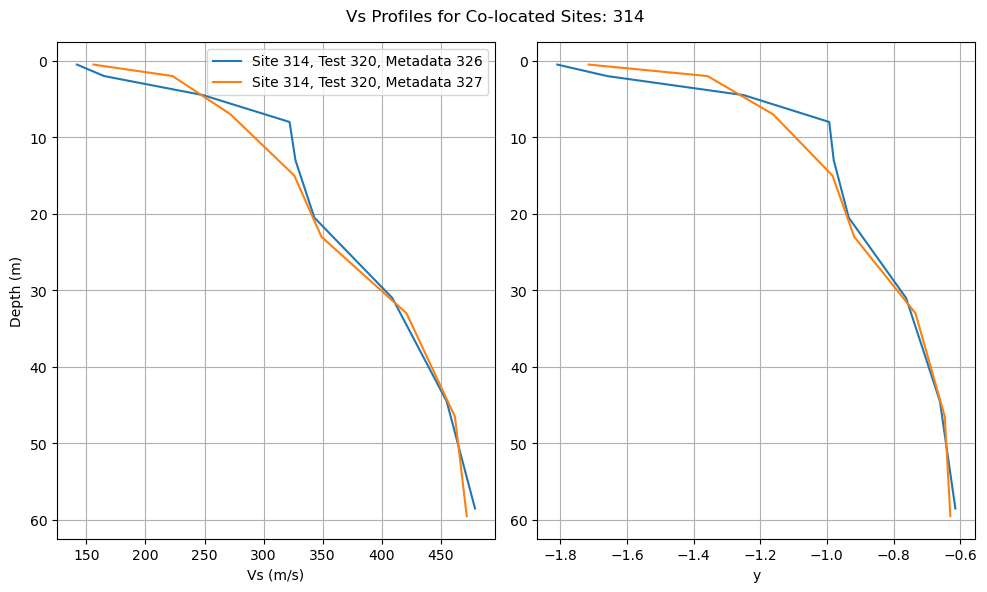

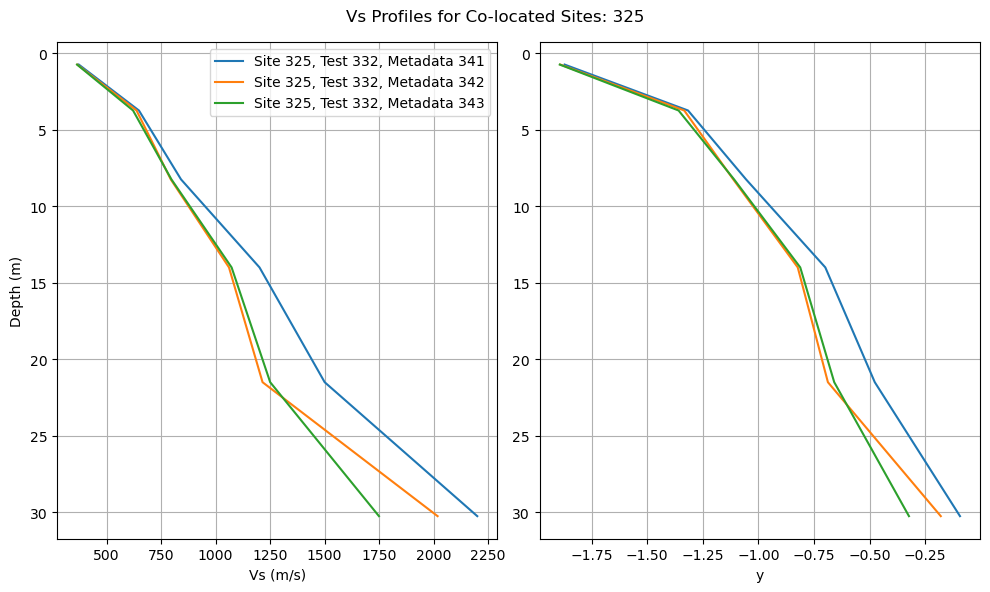

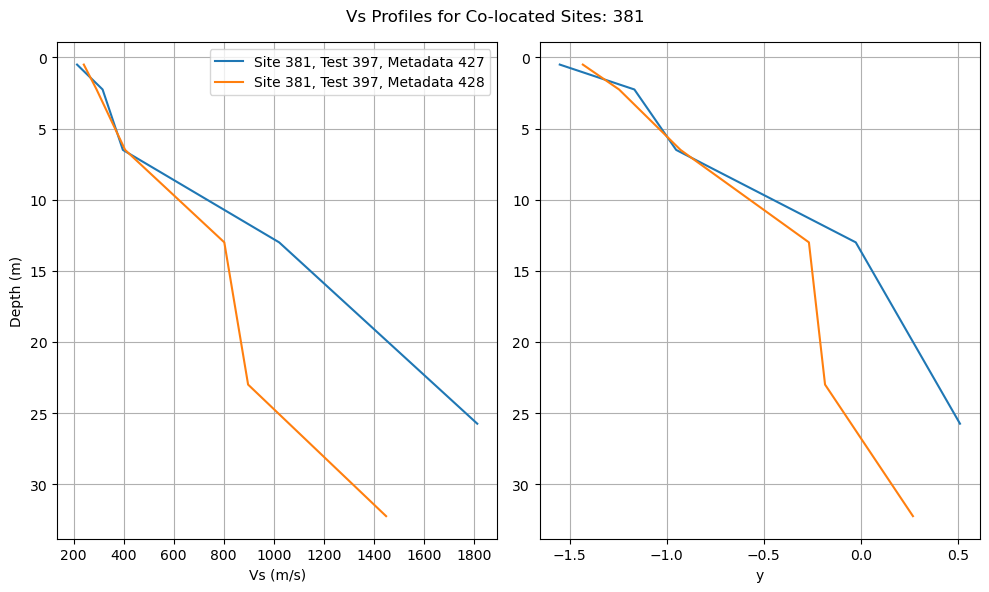

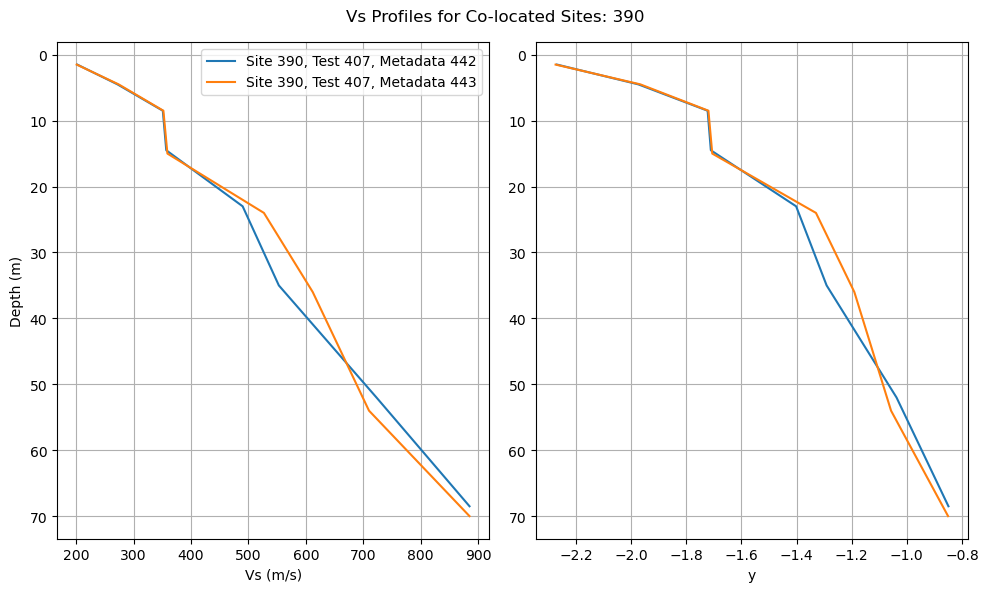

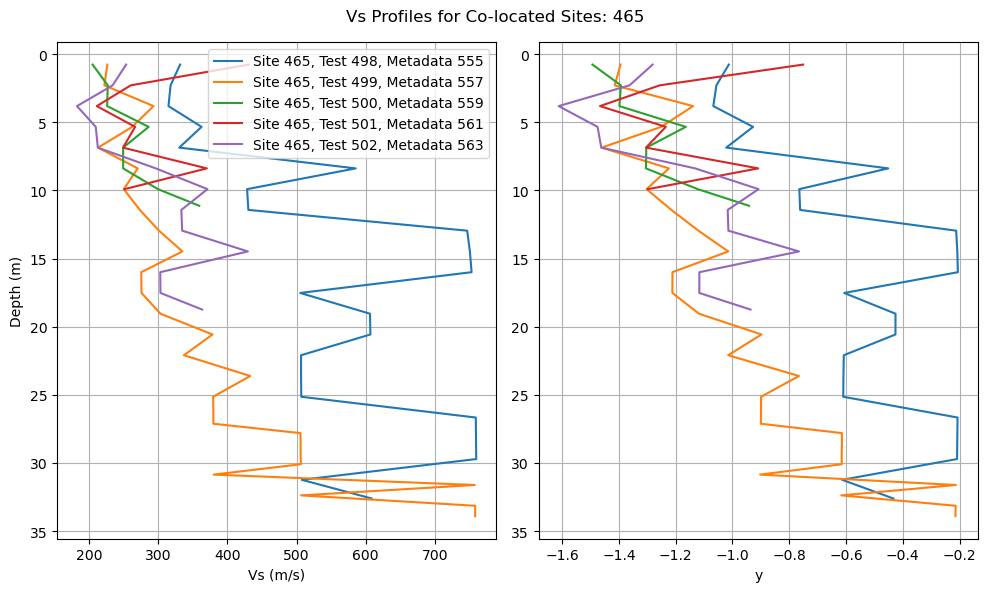

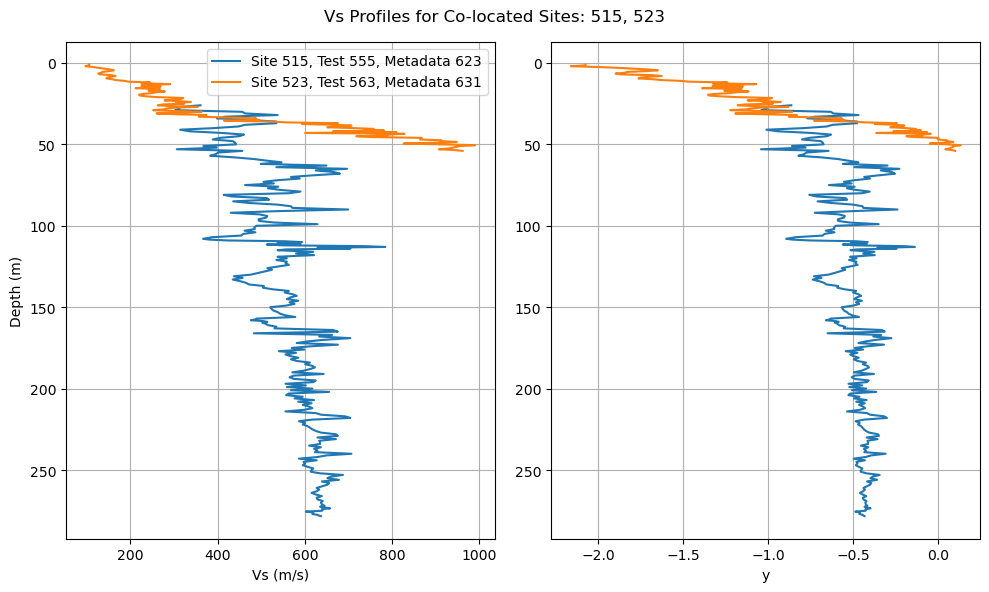

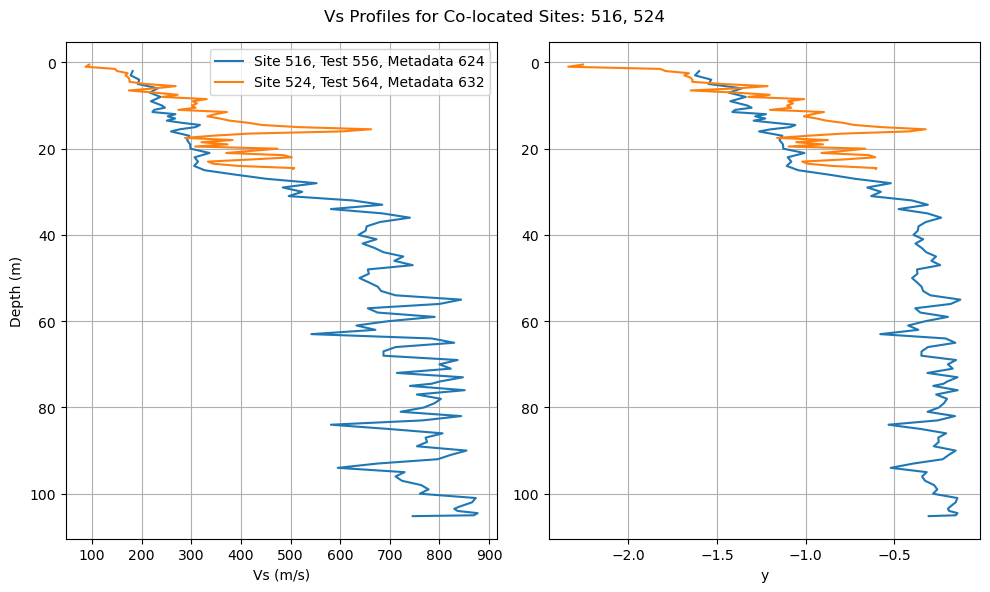

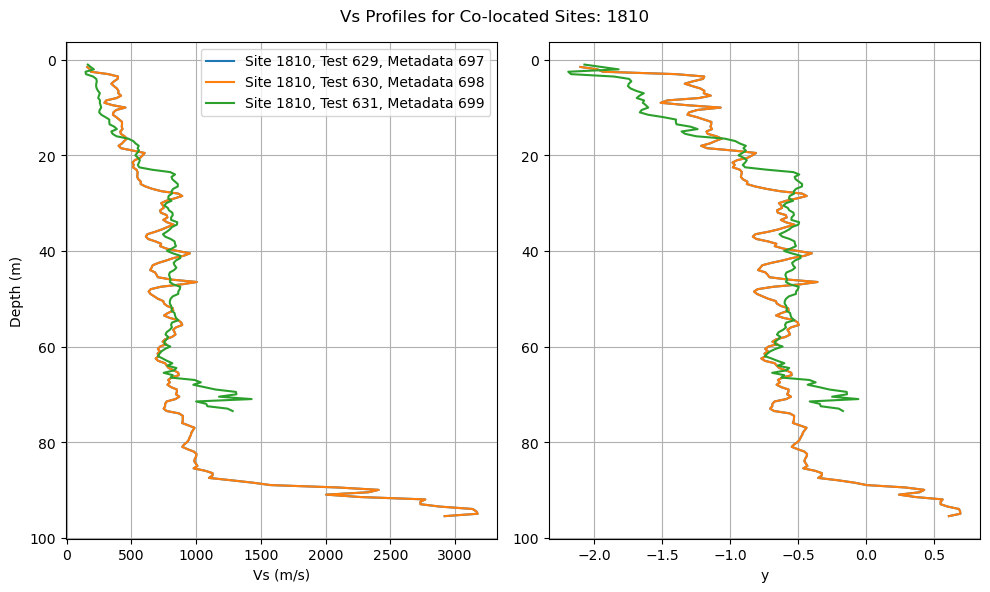

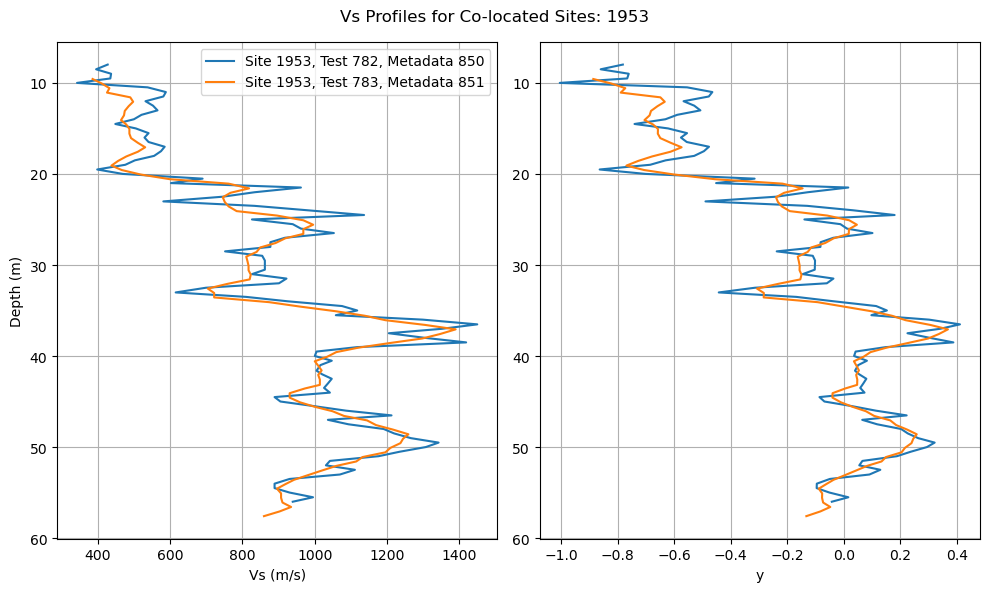

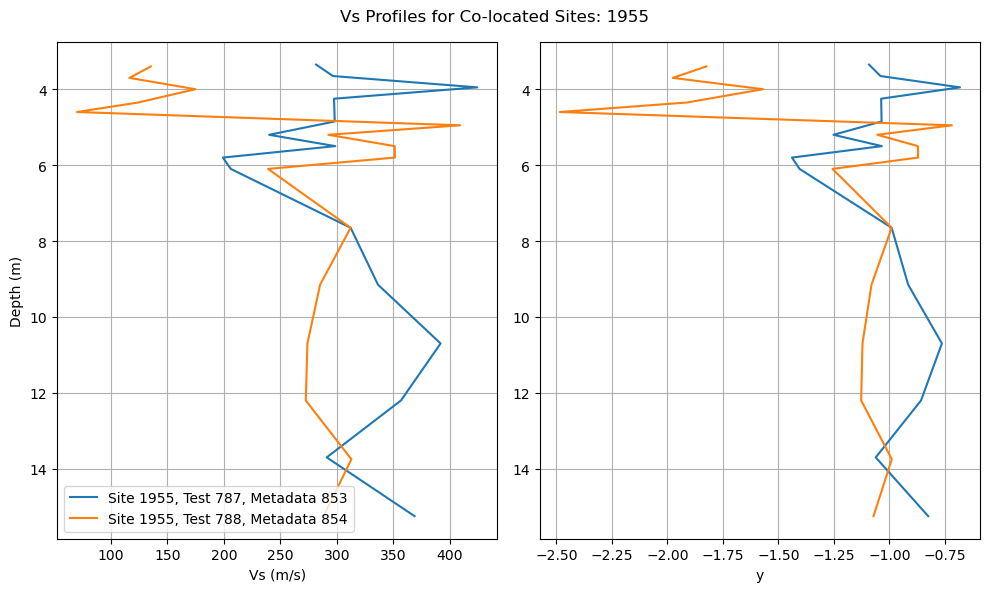

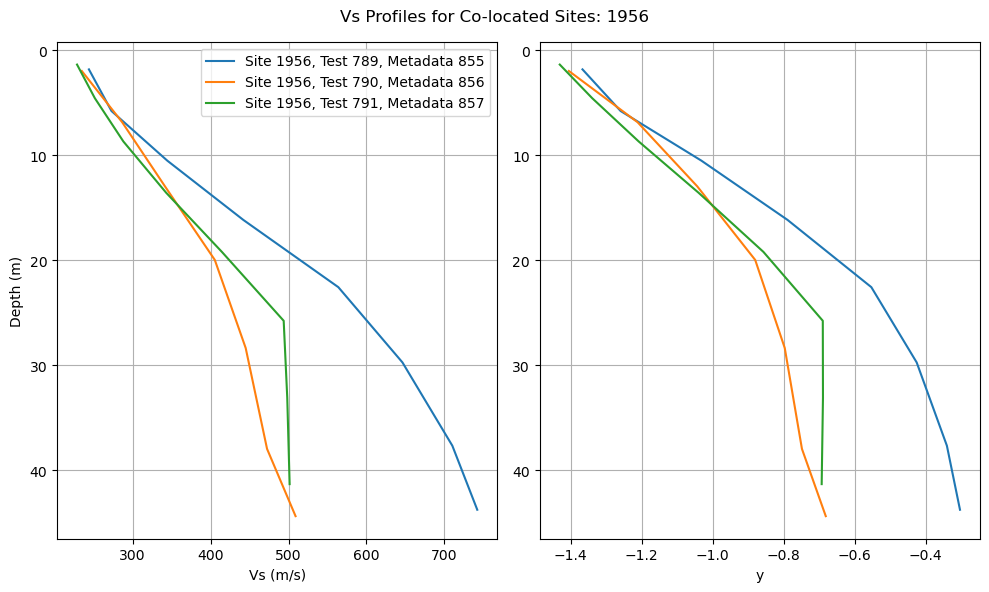

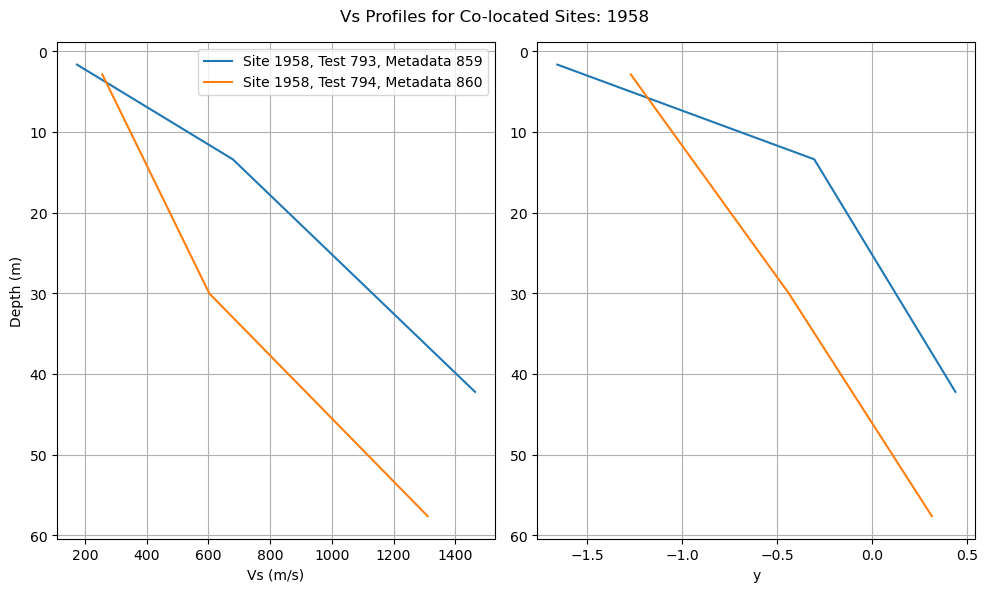

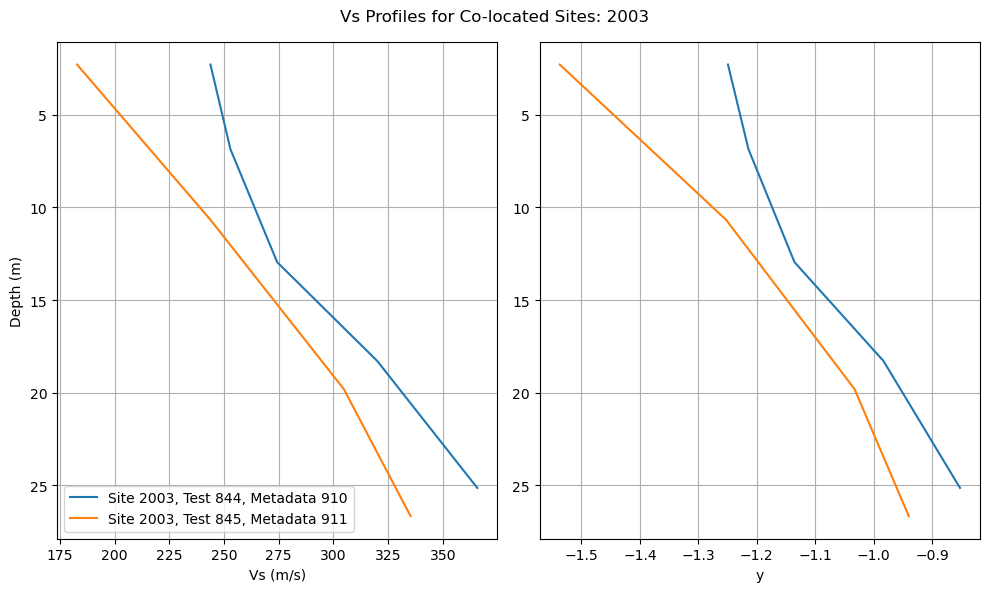

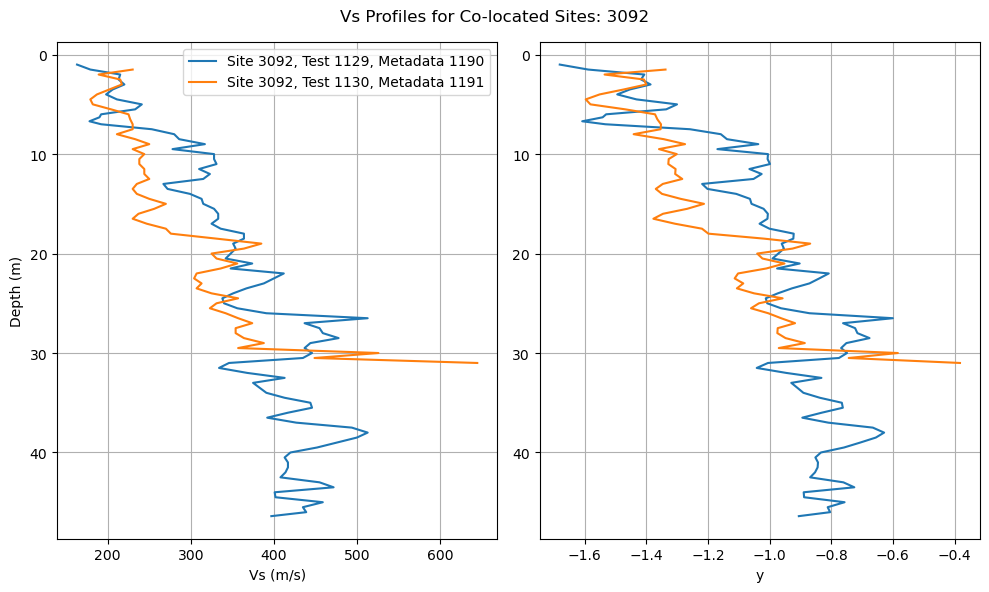

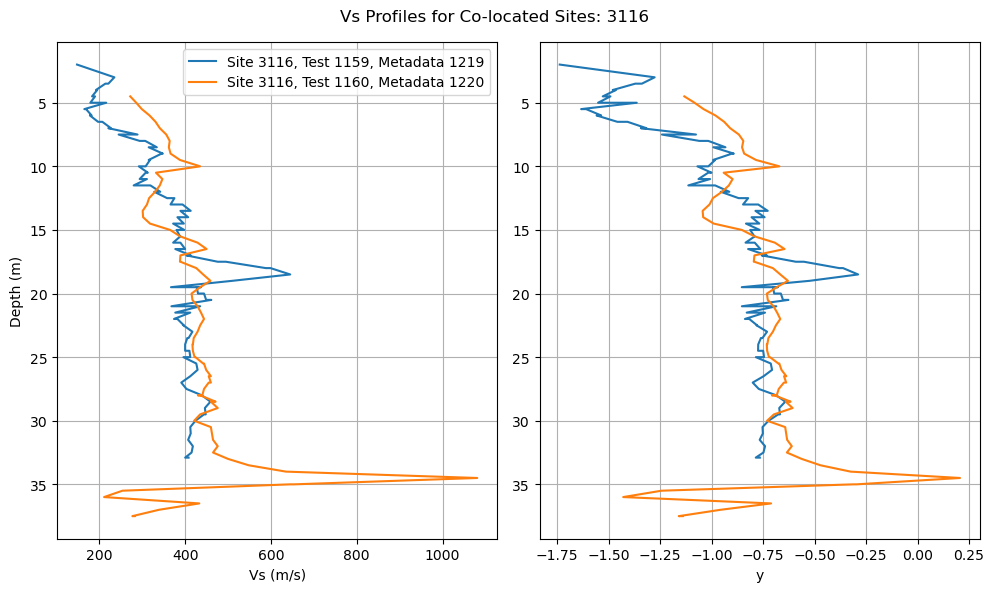

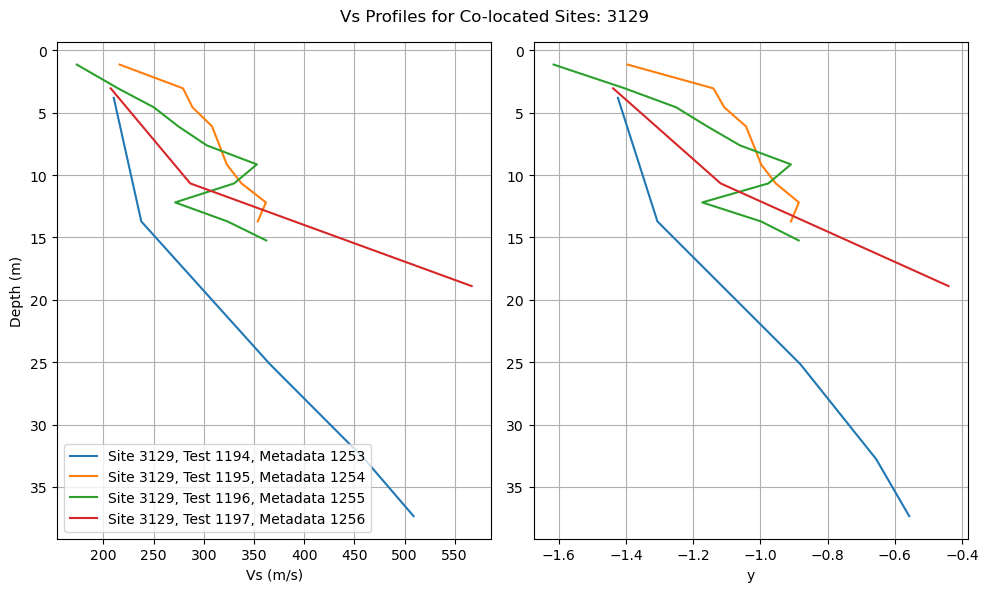

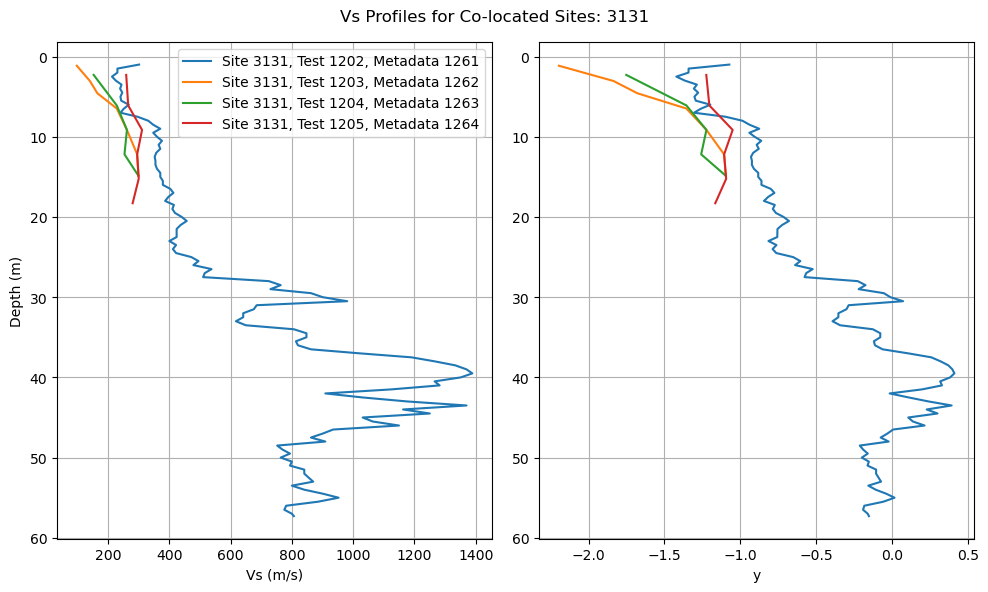

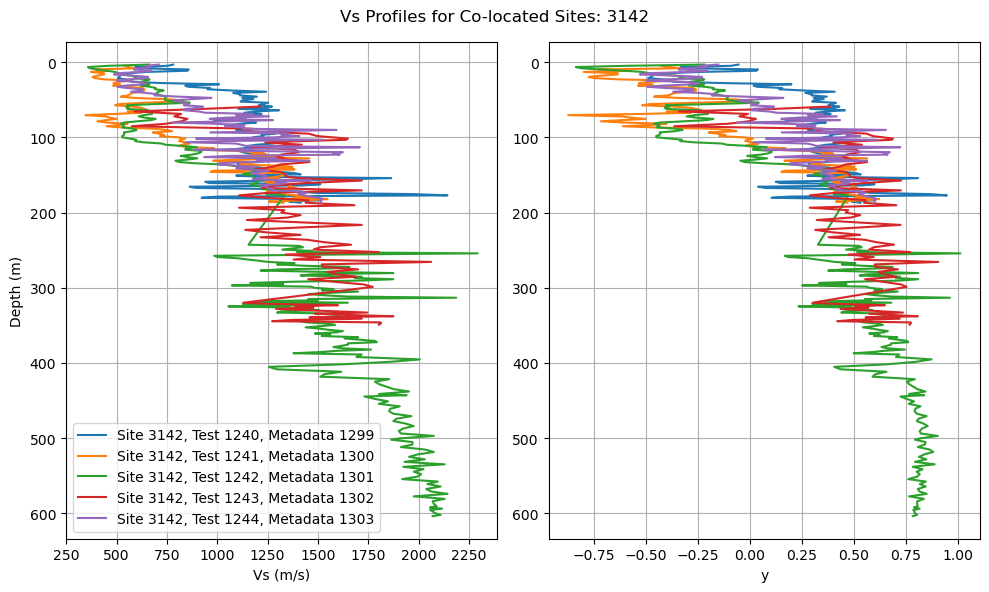

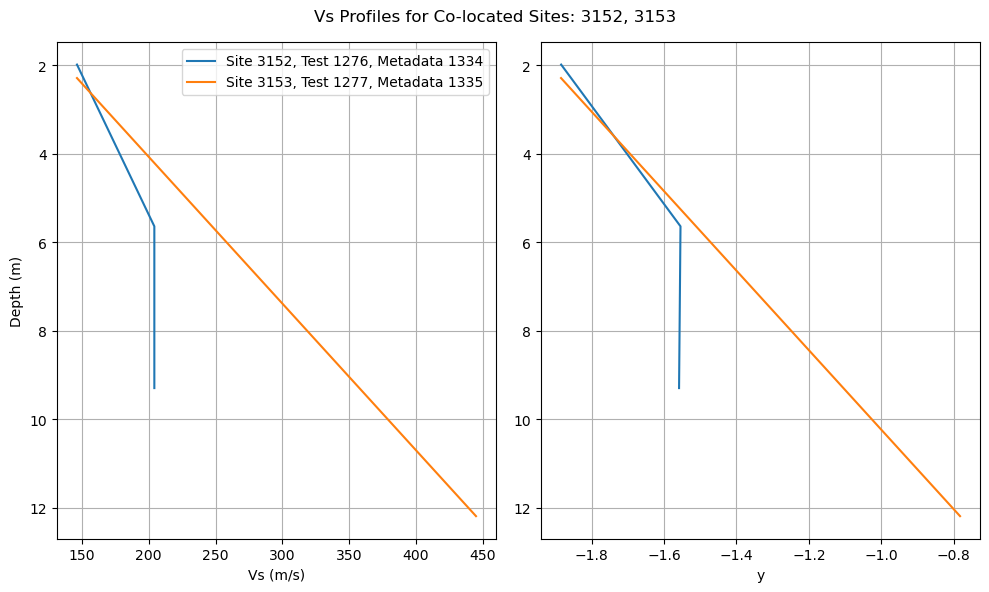

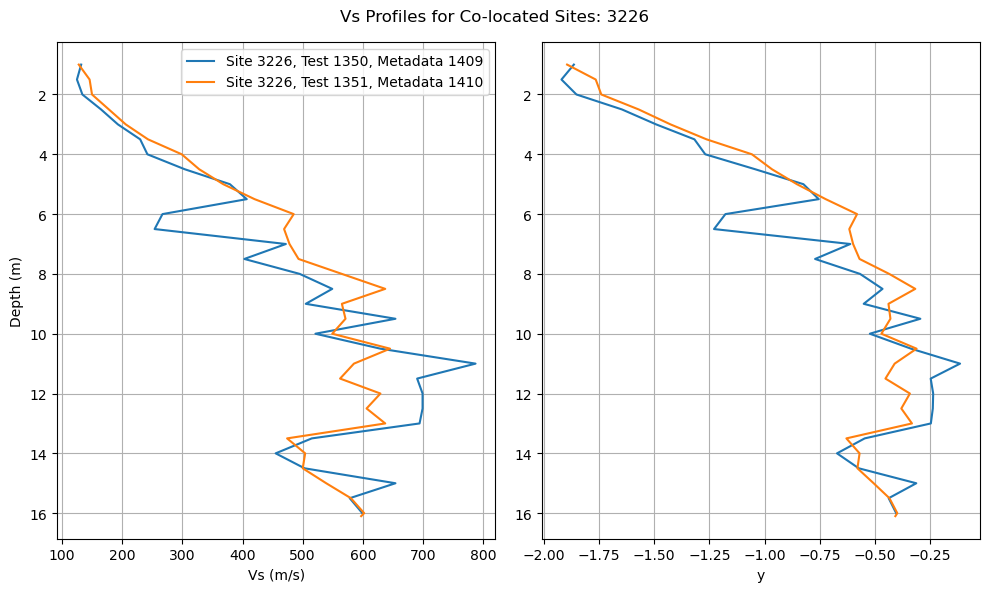

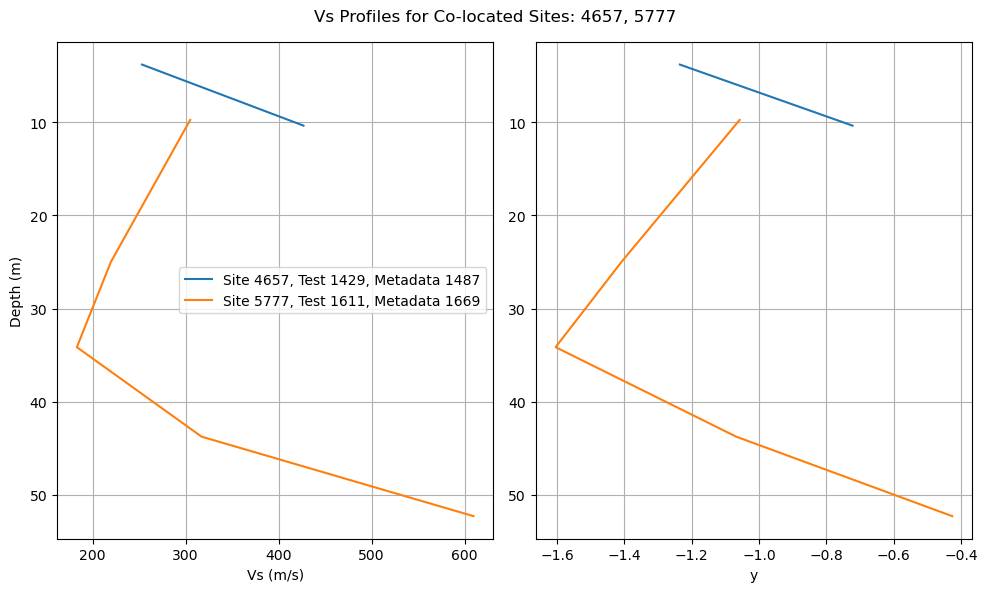

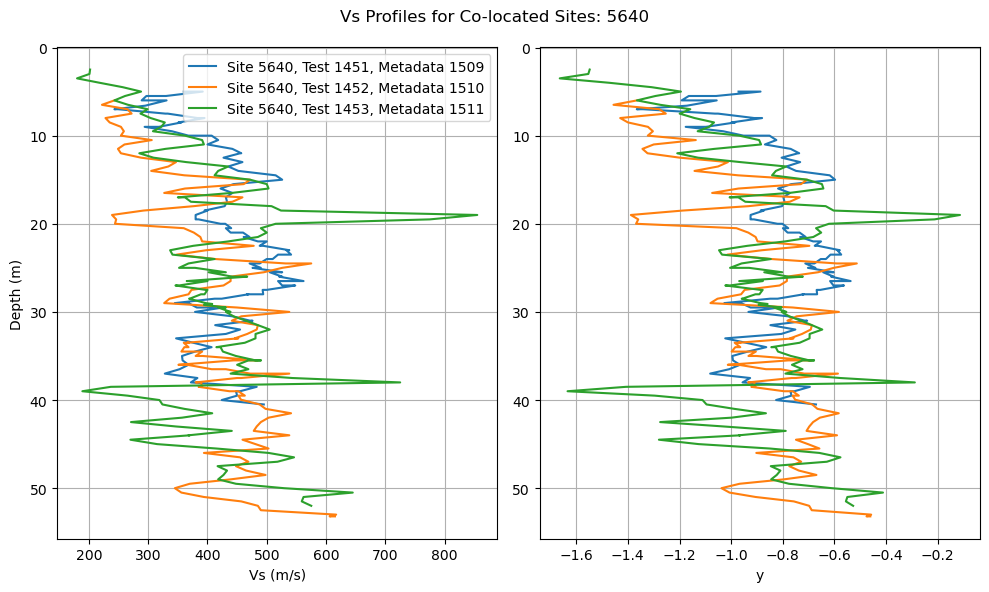

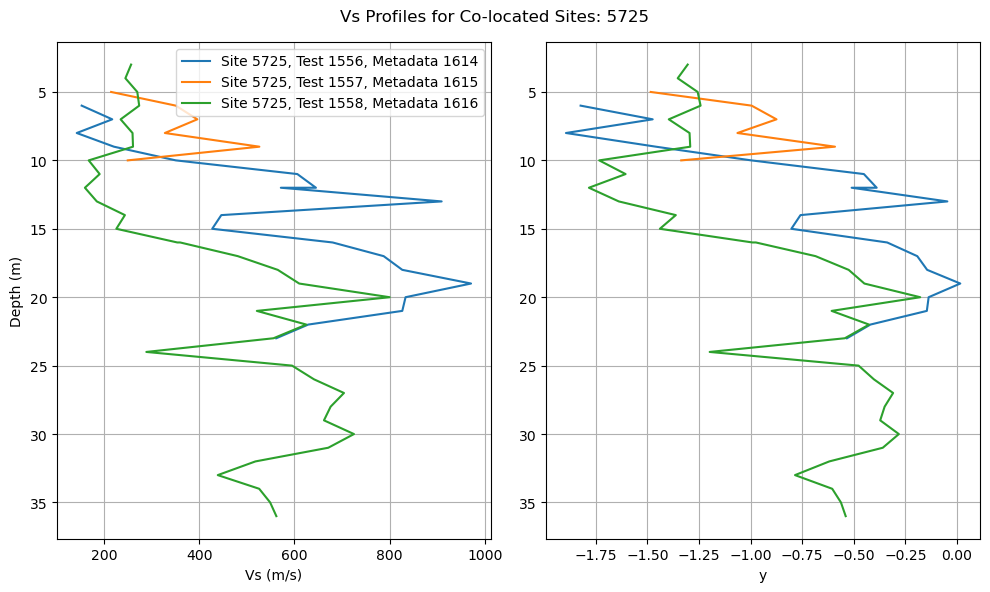

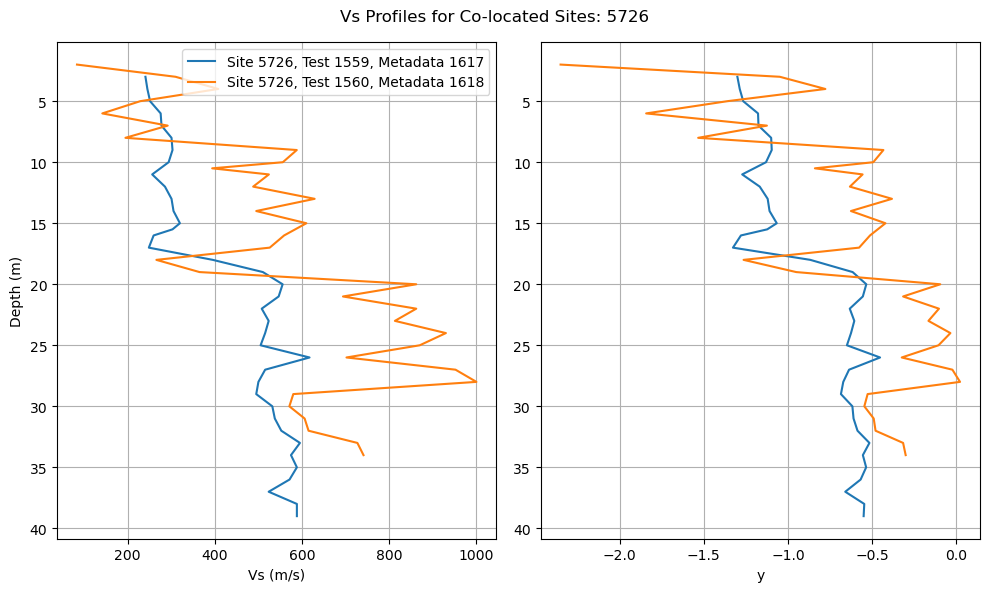

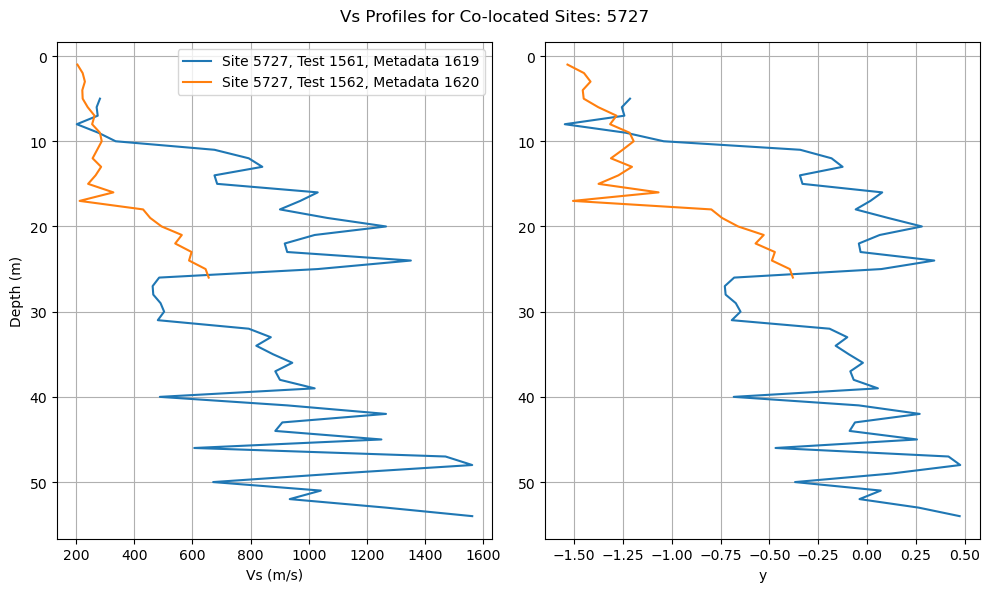

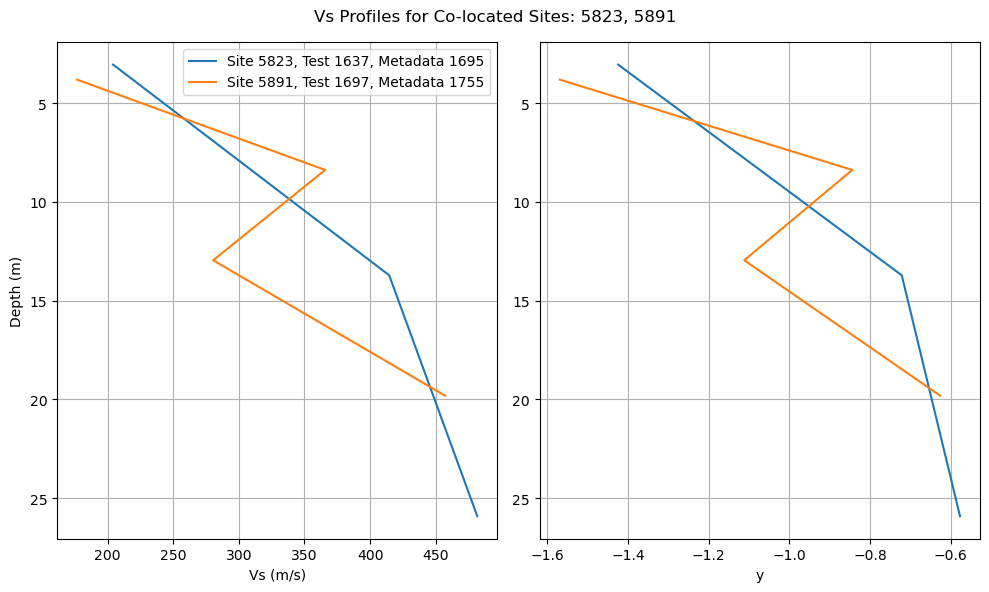

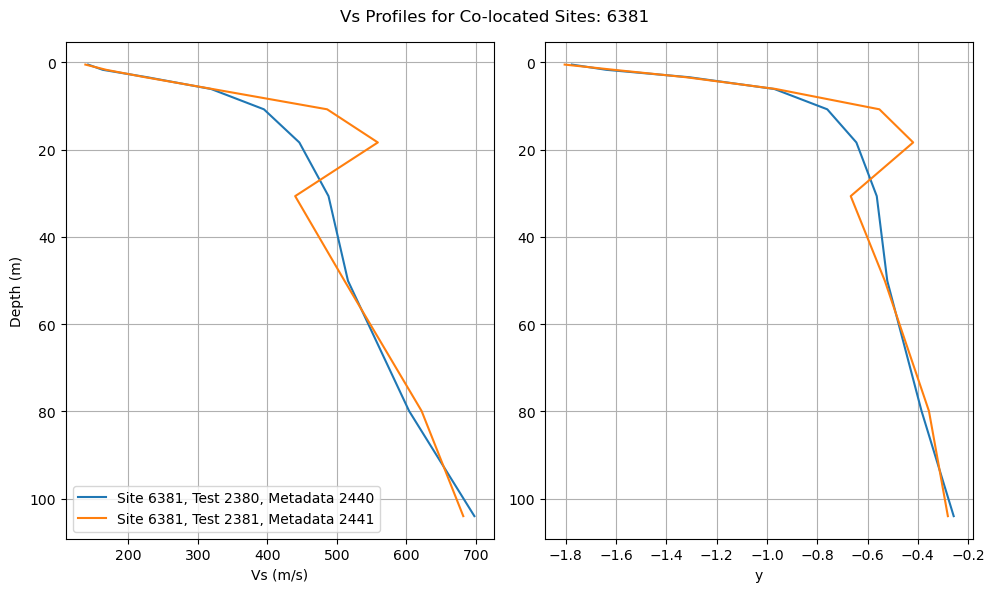

In [15]:
#iterate over groups of colocated sites
for g in list(nx.connected_components(sites_G)):
    #colocated sites
    site_ids = df_sites.loc[list(g), 'site_id'].tolist()

    #identify collocated vel measurements
    df_vs_data_group = df_vs_data[df_vs_data['site_id'].isin(site_ids)]
    if not len(df_vs_data_group): continue
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 6))  # 1 row, 2 columns
    for (mid, sid, tid), prof in df_vs_data_group.groupby(['metadata_id','site_id','test_id']):
        ax1.plot(prof['vs_value'], prof['vs_middle_depth'], label=f'Site {sid}, Test {tid}, Metadata {mid}')
        ax2.plot(prof['diff'], prof['vs_middle_depth'], label=f'Site {sid}, Test {tid}, Metadata {mid}')

    ax1.invert_yaxis()
    ax2.invert_yaxis()
    ax1.set_xlabel('Vs (m/s)')
    ax2.set_xlabel('y')
    ax1.set_ylabel('Depth (m)')
    ax1.legend()
    ax1.grid(True)
    ax2.grid(True)
    
    fig.suptitle(f'Vs Profiles for Co-located Sites: {", ".join(map(str, np.unique(site_ids)))}')
    fig.tight_layout()


#### Collocated Tests

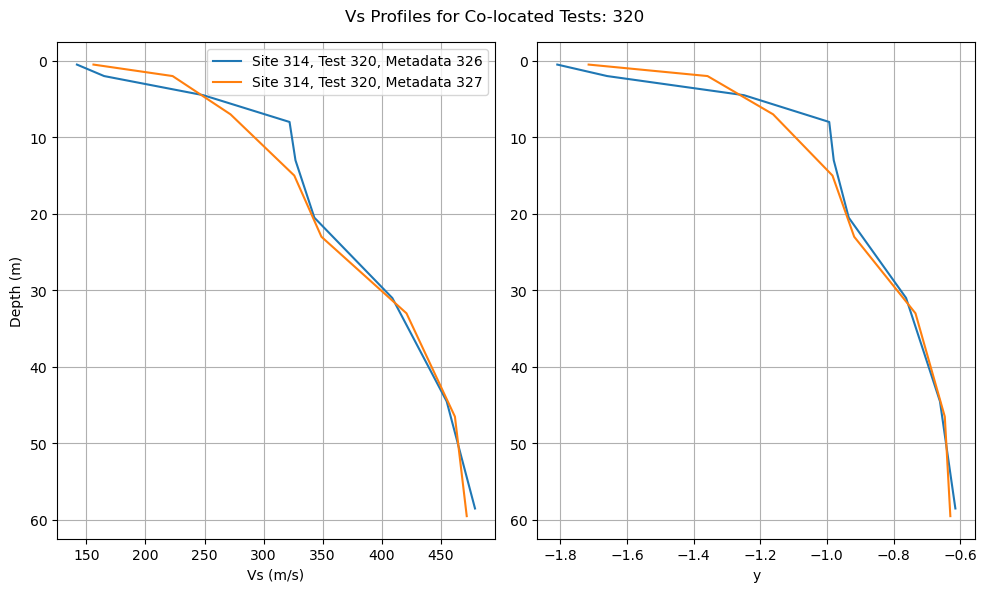

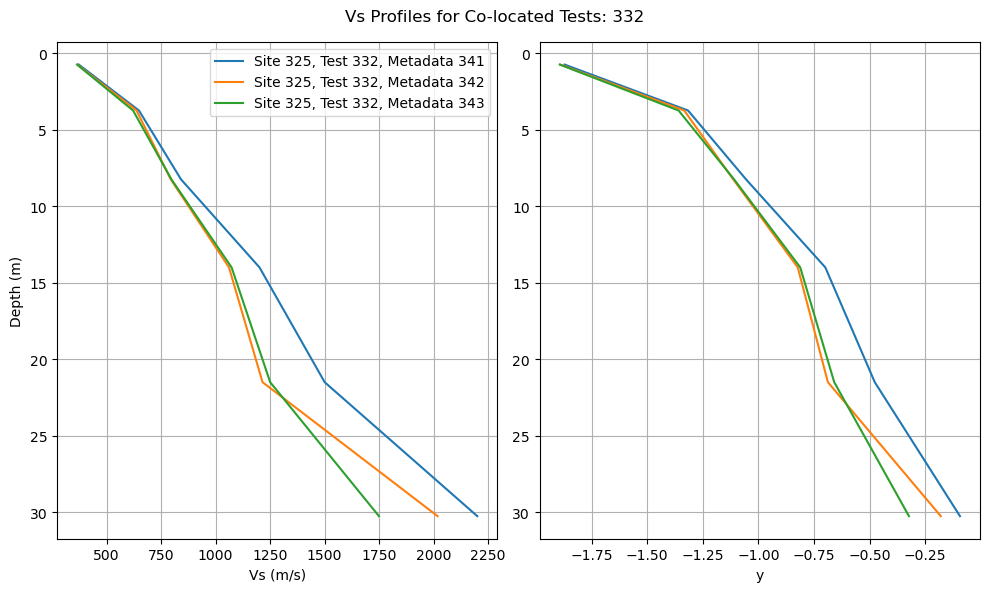

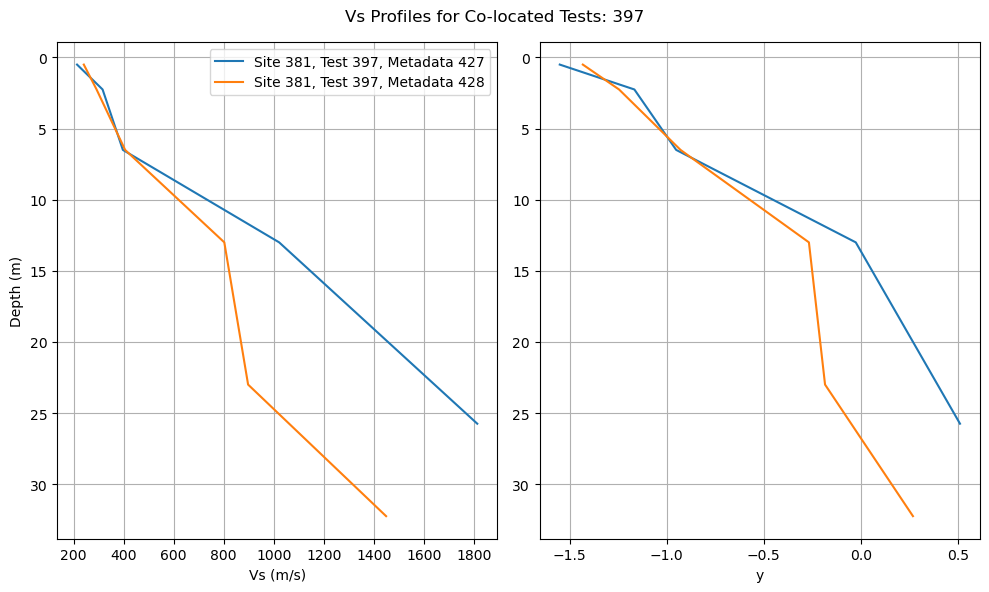

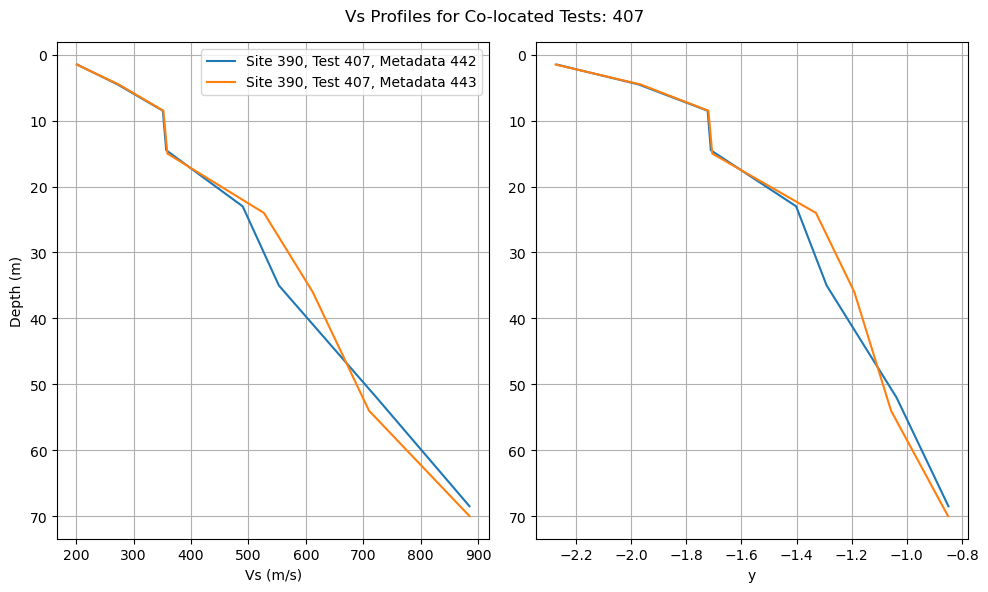

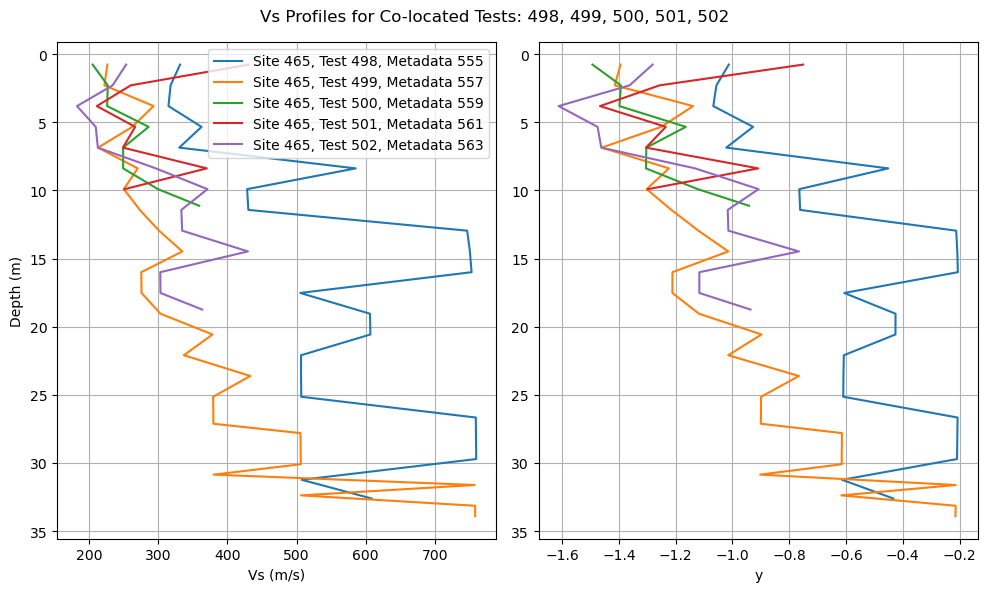

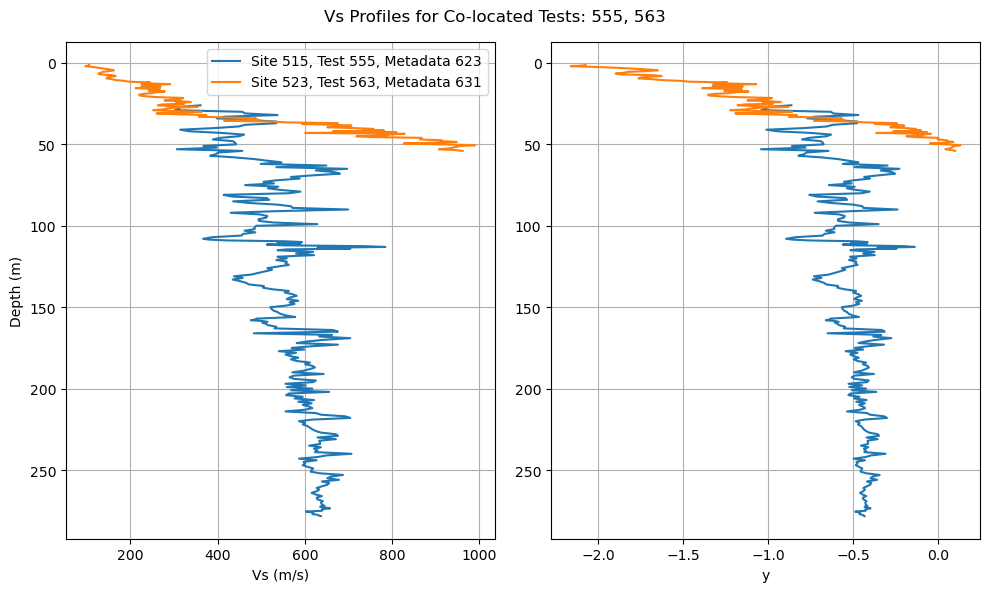

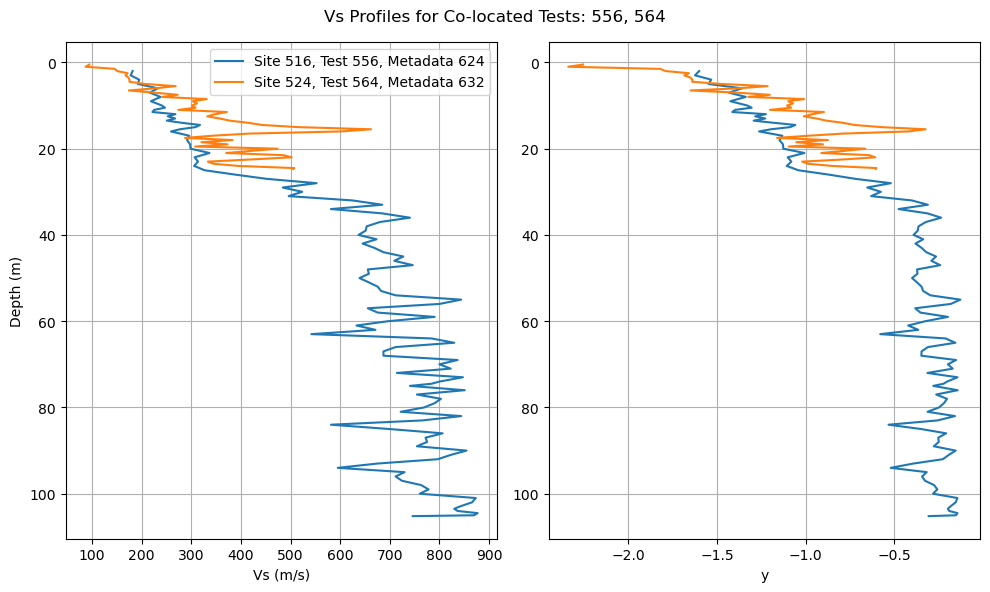

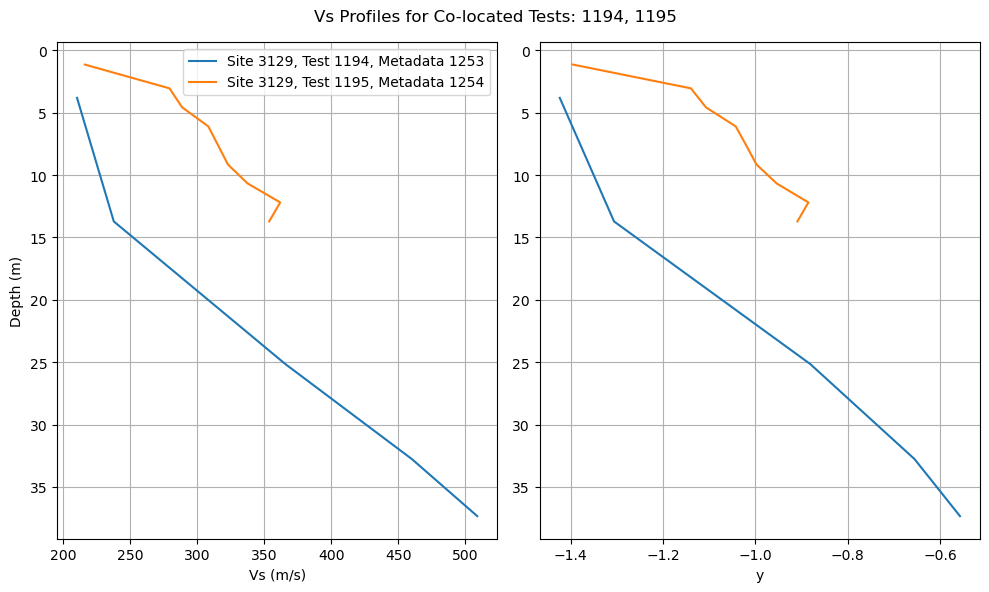

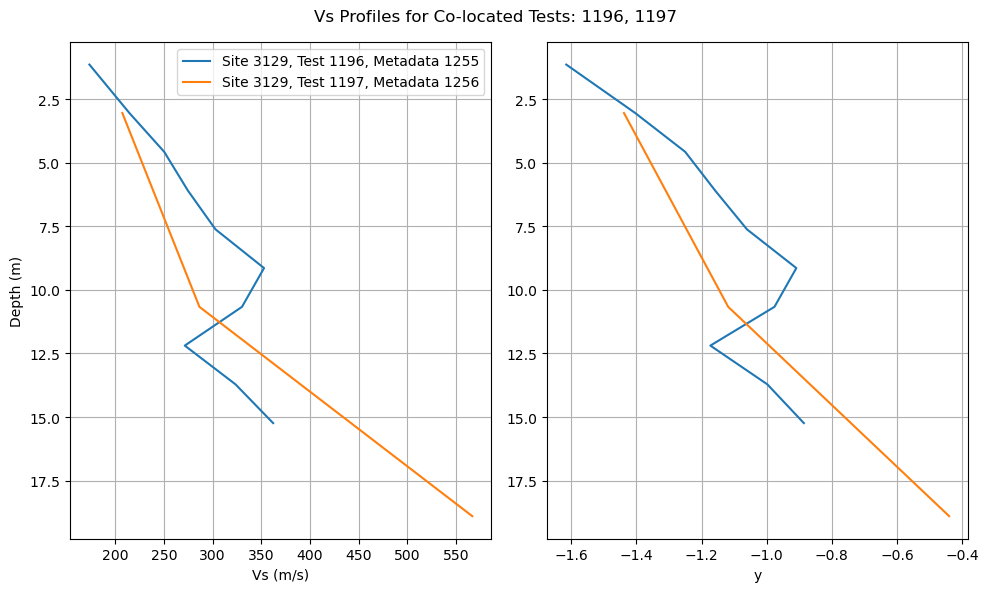

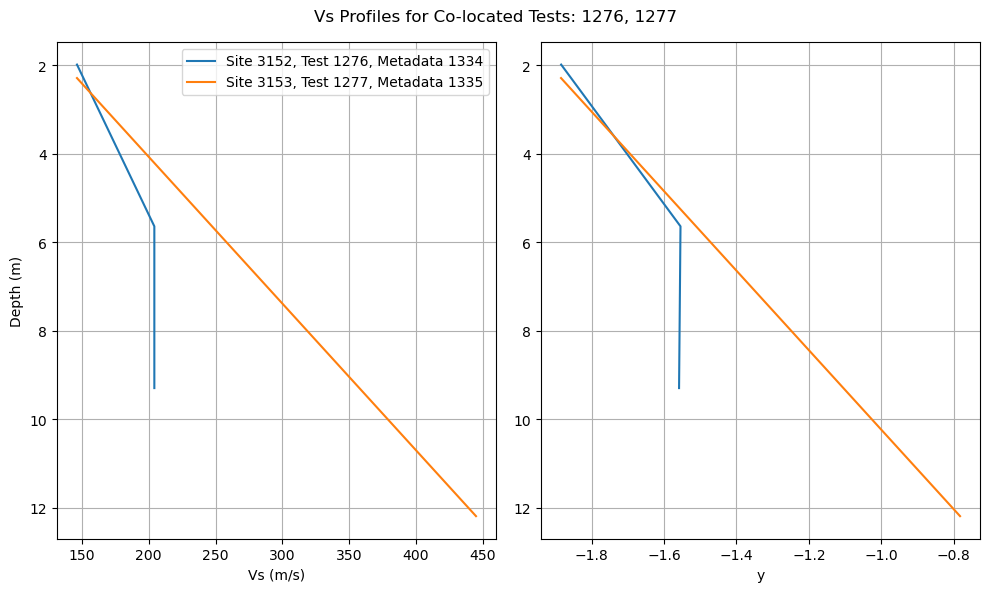

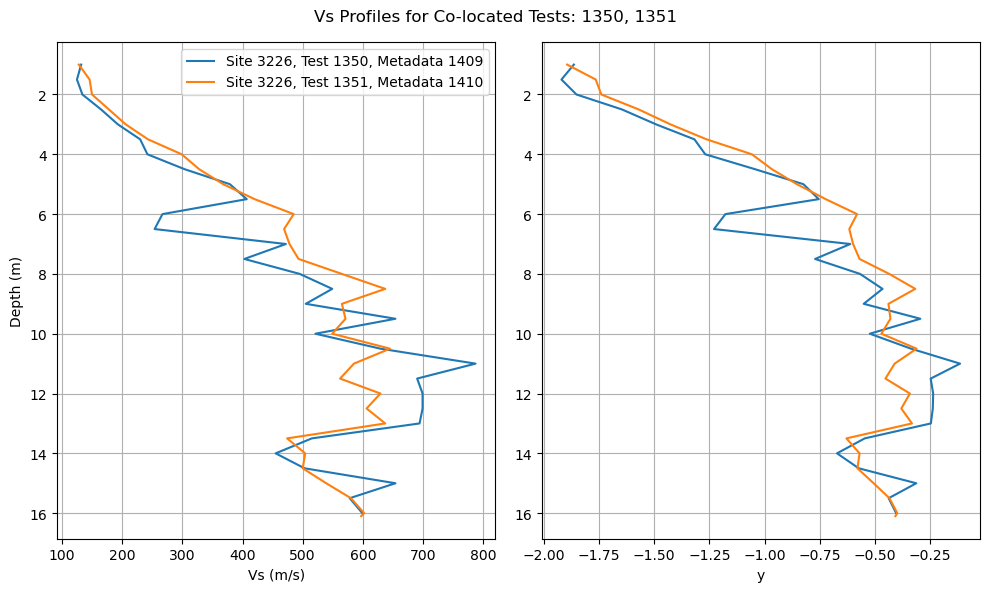

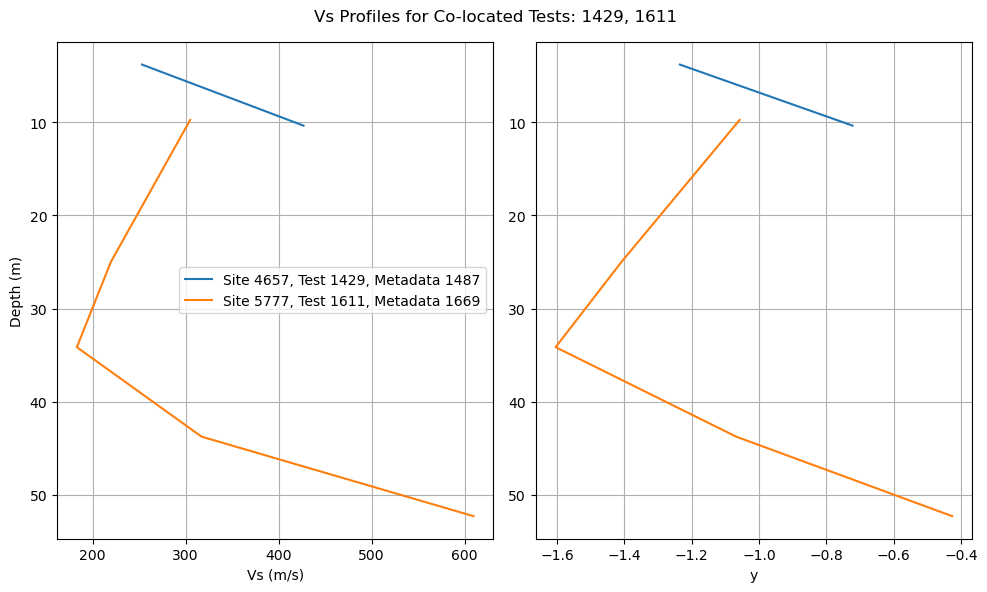

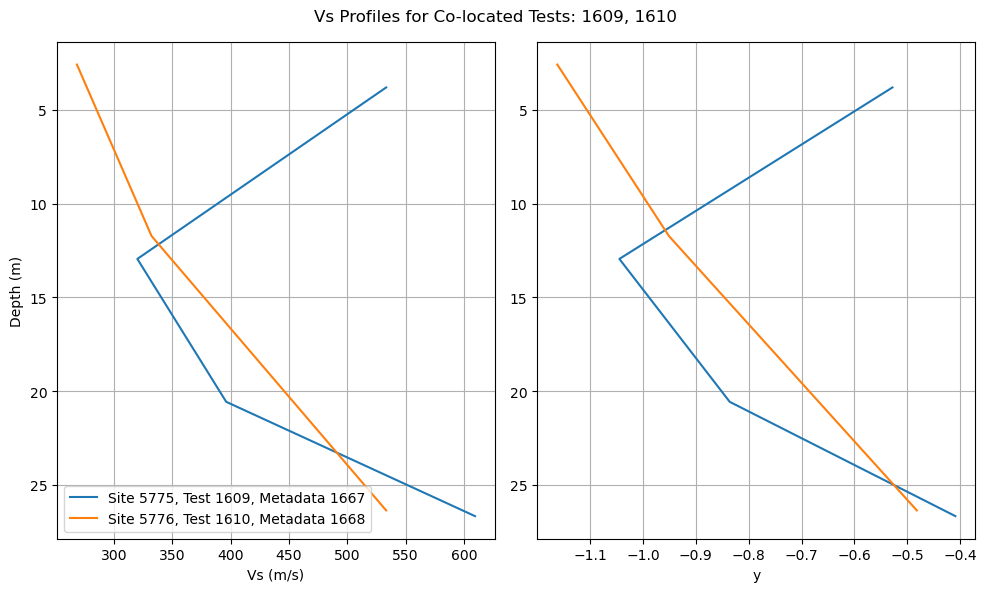

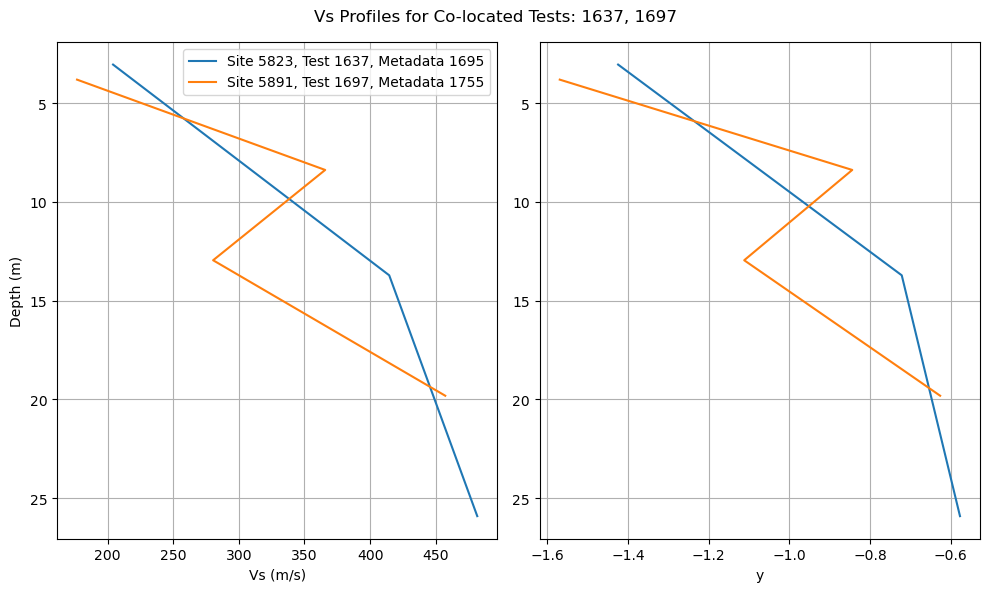

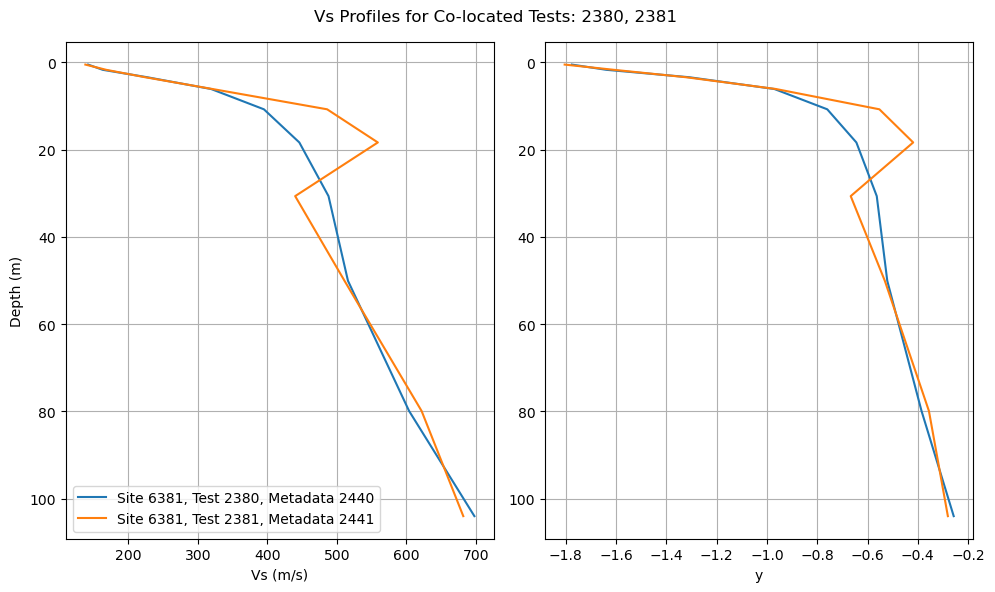

In [16]:
#iterate over groups of colocated tests
for g in list(nx.connected_components(tests_G)):
    #colocated sites
    test_ids = df_sites.loc[list(g), 'test_id'].tolist()

    #group of collocated tests    
    df_vs_data_group = df_vs_data[df_vs_data['test_id'].isin(test_ids)]
    if not len(df_vs_data_group): continue
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 6))  # 1 row, 2 columns
    for (mid, sid, tid), prof in df_vs_data_group.groupby(['metadata_id','site_id','test_id']):
        ax1.plot(prof['vs_value'], prof['vs_middle_depth'], label=f'Site {sid}, Test {tid}, Metadata {mid}')
        ax2.plot(prof['diff'], prof['vs_middle_depth'], label=f'Site {sid}, Test {tid}, Metadata {mid}')

    ax1.invert_yaxis()
    ax2.invert_yaxis()
    ax1.set_xlabel('Vs (m/s)')
    ax2.set_xlabel('y')
    ax1.set_ylabel('Depth (m)')
    ax1.legend()
    ax1.grid(True)
    ax2.grid(True)
    
    fig.suptitle(f'Vs Profiles for Co-located Tests: {", ".join(map(str, np.unique(test_ids)))}')
    fig.tight_layout()

### Indentify Outliers

In [17]:
# site = 325, test = 332, metadata = 341
df_vs_data = df_vs_data.loc[~((df_vs_data.site_id == 325) & 
                              (df_vs_data.test_id == 332) & 
                              (df_vs_data.metadata_id == 341)), :]

# site = 381, test = 397, metadata = 427
df_vs_data = df_vs_data.loc[~((df_vs_data.site_id == 381) & 
                              (df_vs_data.test_id == 397) & 
                              (df_vs_data.metadata_id == 427)), :]

# site = 465, test = 498, metadata = 555
df_vs_data = df_vs_data.loc[~((df_vs_data.site_id == 465) & 
                              (df_vs_data.test_id == 498) & 
                              (df_vs_data.metadata_id == 555)), :]

# site = 523, test = 563, metadata = 631, z > 40
df_vs_data = df_vs_data.loc[~((df_vs_data.site_id == 523) & 
                              (df_vs_data.test_id == 563) & 
                              (df_vs_data.metadata_id == 631) & 
                              (df_vs_data.vs_middle_depth > 36)), :]

# site = 524, test = 564, metadata = 632
df_vs_data = df_vs_data.loc[~((df_vs_data.site_id == 524) & 
                              (df_vs_data.test_id == 564) & 
                              (df_vs_data.metadata_id == 632)), :]

# site = 1810, test = 629, metadata = 697, z > 88
df_vs_data = df_vs_data.loc[~((df_vs_data.site_id == 1810) & 
                              (df_vs_data.test_id == 629) & 
                              (df_vs_data.metadata_id == 697) & 
                              (df_vs_data.vs_middle_depth > 88)), :]

# site = 1810, test = 630, metadata = 698, z > 88
df_vs_data = df_vs_data.loc[~((df_vs_data.site_id == 1810) & 
                              (df_vs_data.test_id == 630) & 
                              (df_vs_data.metadata_id == 698) & 
                              (df_vs_data.vs_middle_depth > 88)), :]

# site = 1955, test = 788, metadata = 854
df_vs_data = df_vs_data.loc[~((df_vs_data.site_id == 1955) & 
                              (df_vs_data.test_id == 788) & 
                              (df_vs_data.metadata_id == 854)), :]

# site = 1956, test = 789, metadata = 855
df_vs_data = df_vs_data.loc[~((df_vs_data.site_id == 1956) & 
                              (df_vs_data.test_id == 789) & 
                              (df_vs_data.metadata_id == 855)), :]

# site = 1958, test = 793, metadata = 859
df_vs_data = df_vs_data.loc[~((df_vs_data.site_id == 1958) & 
                              (df_vs_data.test_id == 794) & 
                              (df_vs_data.metadata_id == 860)), :]

# site = 3092, test = 1130, metadata = 1191, z > 30
df_vs_data = df_vs_data.loc[~((df_vs_data.site_id == 3092) & 
                              (df_vs_data.test_id == 1130) & 
                              (df_vs_data.metadata_id == 1191) & 
                              (df_vs_data.vs_middle_depth > 30)), :]

# site = 3116, test = 1160, metadata = 1220, z > 30
df_vs_data = df_vs_data.loc[~((df_vs_data.site_id == 3116) & 
                              (df_vs_data.test_id == 1160) & 
                              (df_vs_data.metadata_id == 1220) & 
                              (df_vs_data.vs_middle_depth > 30)), :]

# site = 3129, test = 1194, metadata = 1253
df_vs_data = df_vs_data.loc[~((df_vs_data.site_id == 3129) & 
                              (df_vs_data.test_id == 1194) & 
                              (df_vs_data.metadata_id == 1253)), :]

# site = 3152, test = 1276, metadata = 1334
df_vs_data = df_vs_data.loc[~((df_vs_data.site_id == 3152) & 
                              (df_vs_data.test_id == 1276) & 
                              (df_vs_data.metadata_id == 1334)), :]

# site = 3153, test = 1277, metadata = 1335
df_vs_data = df_vs_data.loc[~((df_vs_data.site_id == 3153) & 
                              (df_vs_data.test_id == 1277) & 
                              (df_vs_data.metadata_id == 1335)), :]

# site = 4657, test = 1429, metadata = 1487
df_vs_data = df_vs_data.loc[~((df_vs_data.site_id == 4657) & 
                              (df_vs_data.test_id == 1429) & 
                              (df_vs_data.metadata_id == 1487)), :]

# site = 5640, test = 1453, metadata = 1551, z > 36
df_vs_data = df_vs_data.loc[~((df_vs_data.site_id == 5640) & 
                              (df_vs_data.test_id == 1453) & 
                              (df_vs_data.metadata_id == 1511) & 
                              (df_vs_data.vs_middle_depth > 36)), :]

# site = 5640, test = 1453, metadata = 1511, z in [18, 20)
df_vs_data = df_vs_data.loc[~((df_vs_data.site_id == 5640) & 
                              (df_vs_data.test_id == 1453) & 
                              (df_vs_data.metadata_id == 1511) & 
                              (df_vs_data.vs_middle_depth >= 18) & 
                              (df_vs_data.vs_middle_depth < 20)), :]

# site = 5727, test = 1561, metadata = 1619, z < 26
df_vs_data = df_vs_data.loc[~((df_vs_data.site_id == 5727) & 
                              (df_vs_data.test_id == 1561) & 
                              (df_vs_data.metadata_id == 1619) & 
                              (df_vs_data.vs_middle_depth < 26)), :]

# site = 5775, test = 1609, metadata = 1667
df_vs_data = df_vs_data.loc[~((df_vs_data.site_id == 5775) & 
                              (df_vs_data.test_id == 1609) & 
                              (df_vs_data.metadata_id == 1667)), :]

# site = 5777, test = 1611, metadata = 1669
df_vs_data = df_vs_data.loc[~((df_vs_data.site_id == 5777) & 
                              (df_vs_data.test_id == 1611) & 
                              (df_vs_data.metadata_id == 1669)), :]

#remove unreasonable profiles
df_vs_data = df_vs_data[df_vs_data['metadata_id'] != 1301] #deep suspension logging with diverging vs at large depths in Long Beach
df_vs_data = df_vs_data[df_vs_data['metadata_id'] != 1302]
df_vs_data = df_vs_data[df_vs_data['metadata_id'] != 1402] #single measurement profile with very log vs

#### Collocated Sites

/tmp/ipykernel_1009804/2144937789.py:10: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 6))  # 1 row, 2 columns


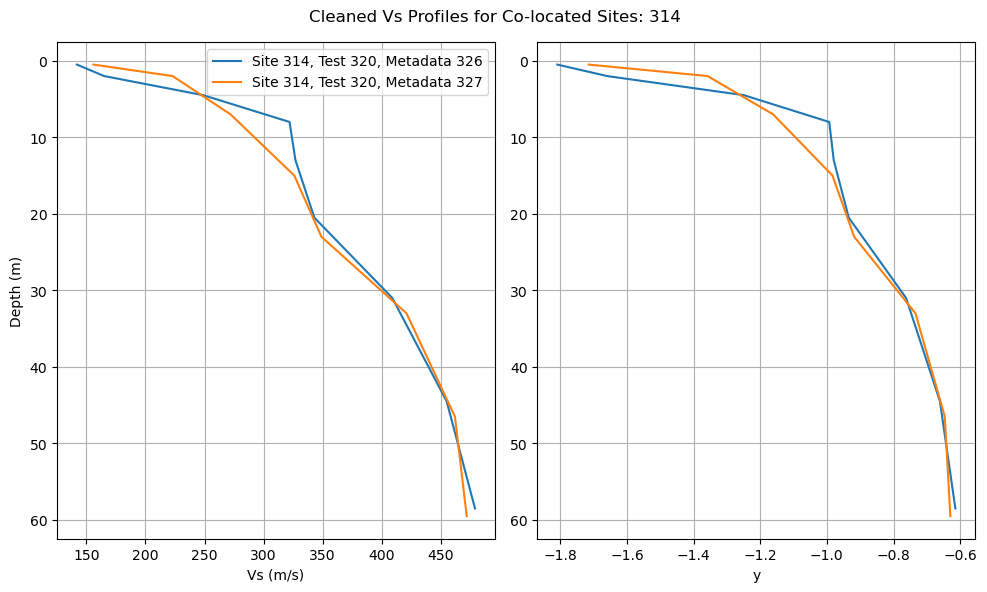

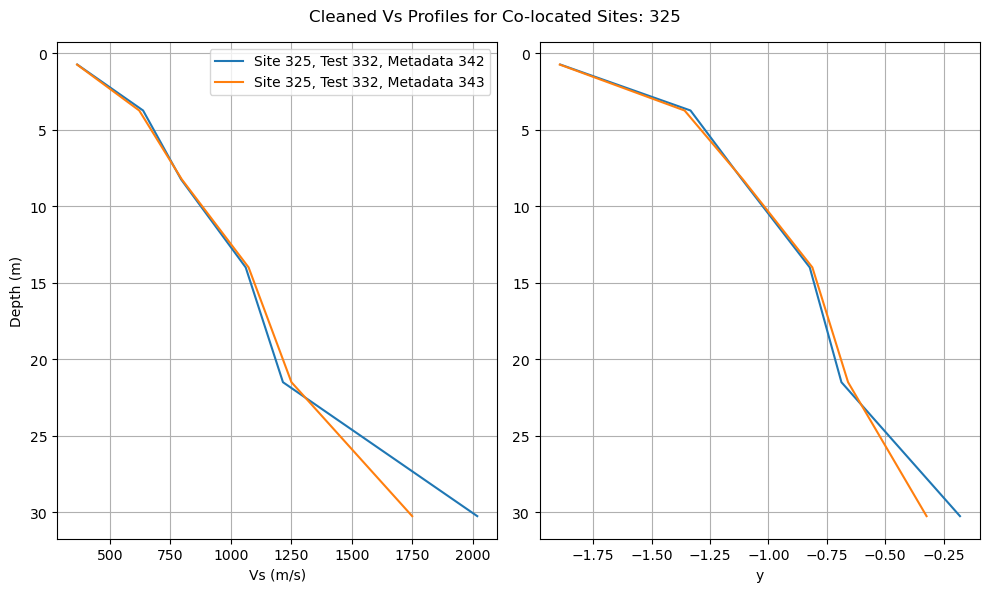

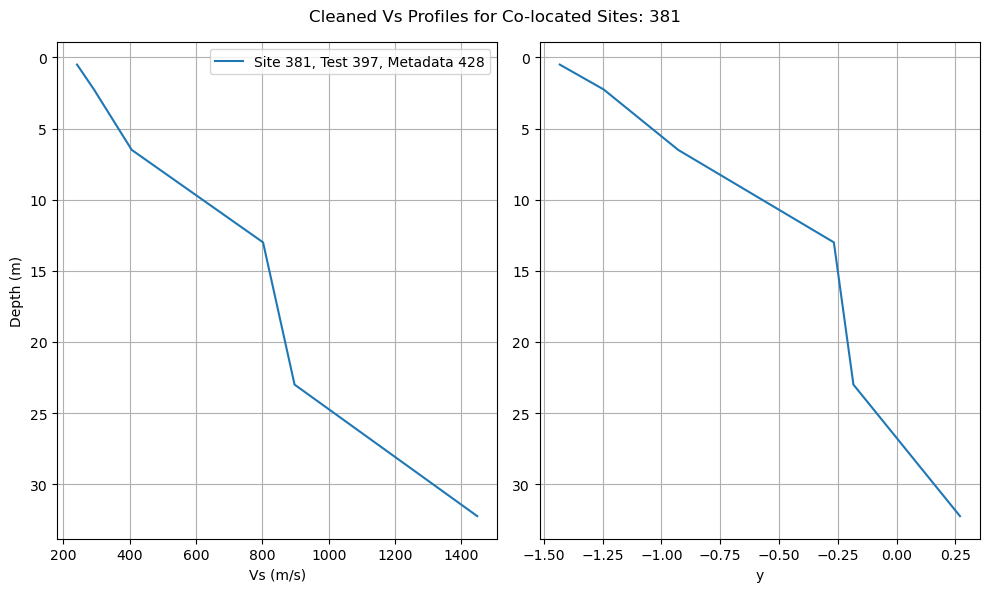

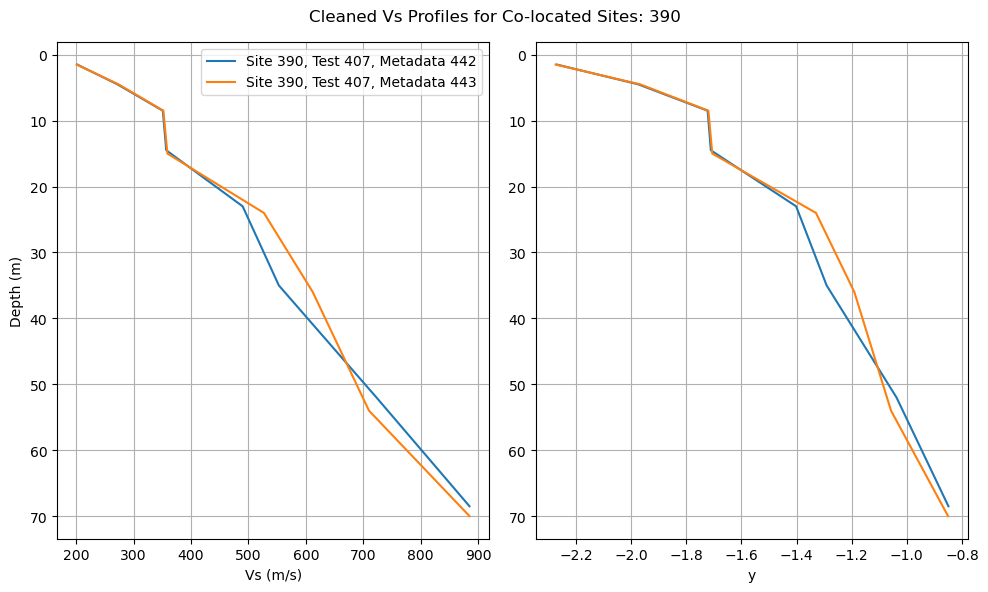

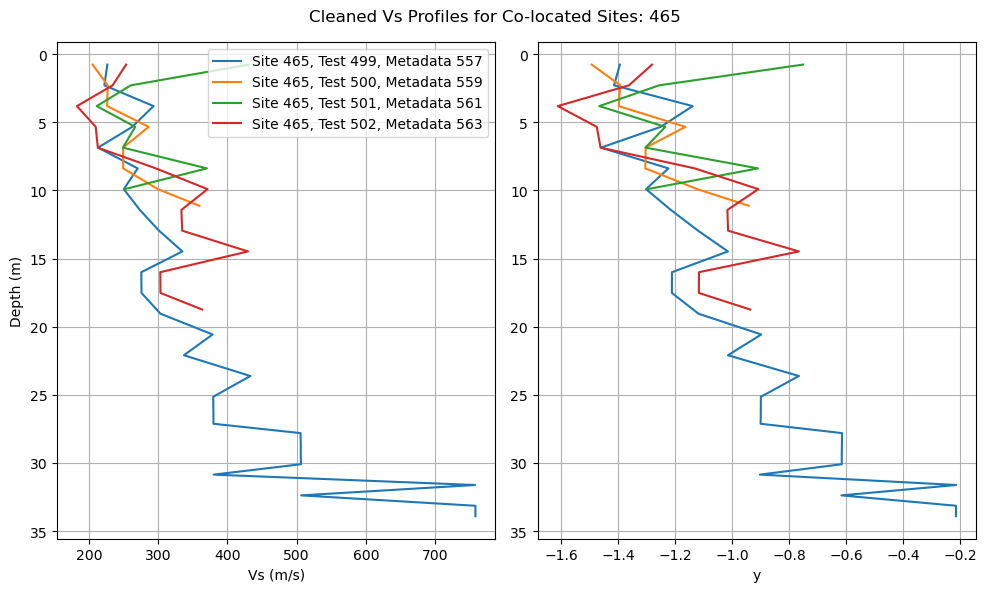

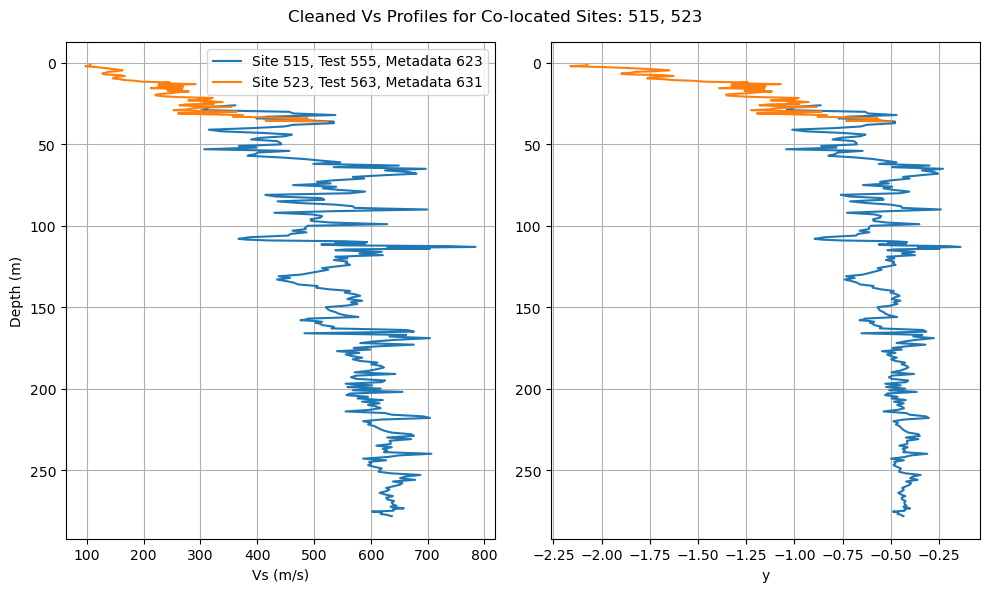

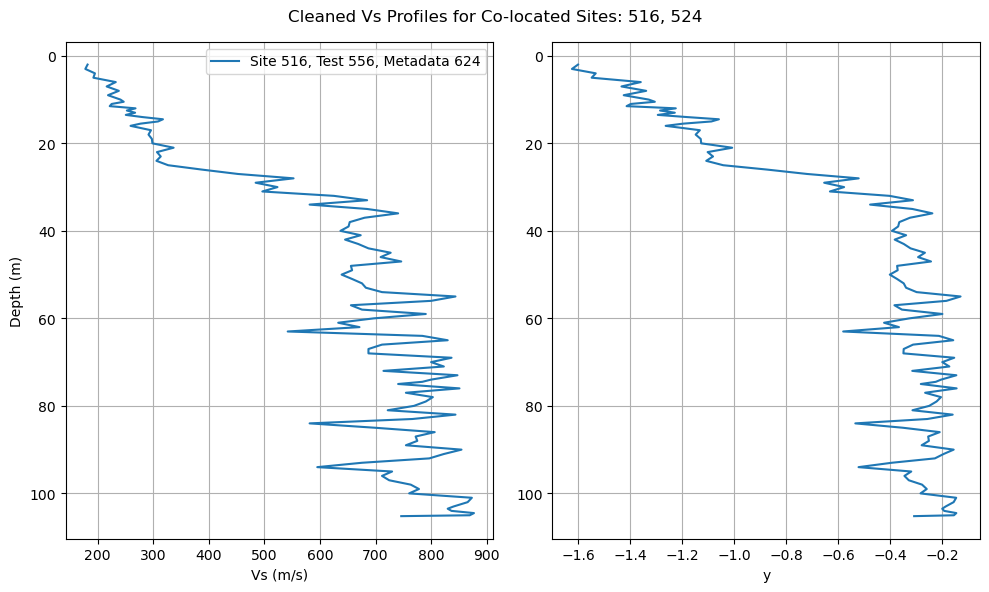

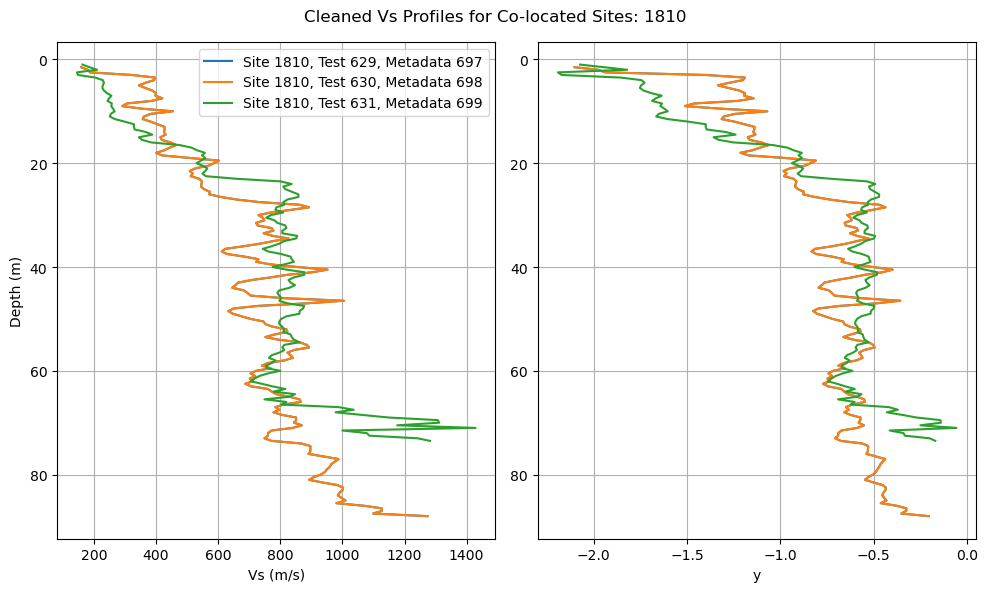

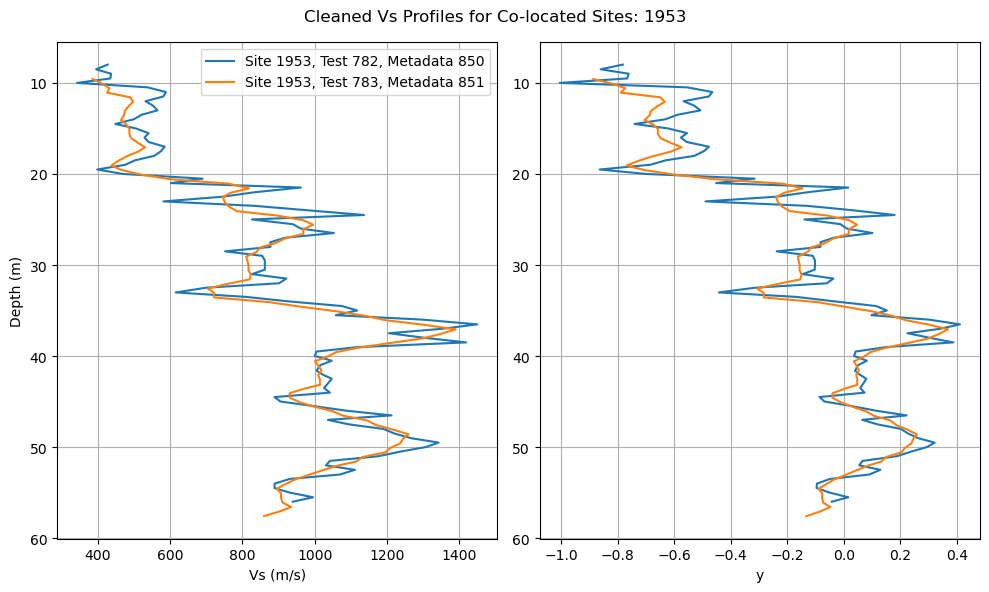

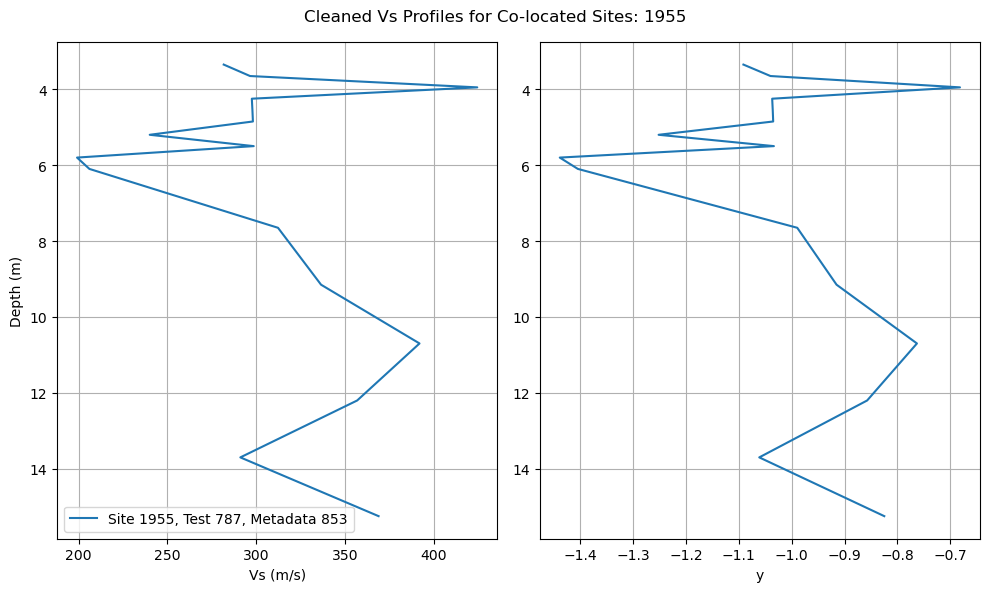

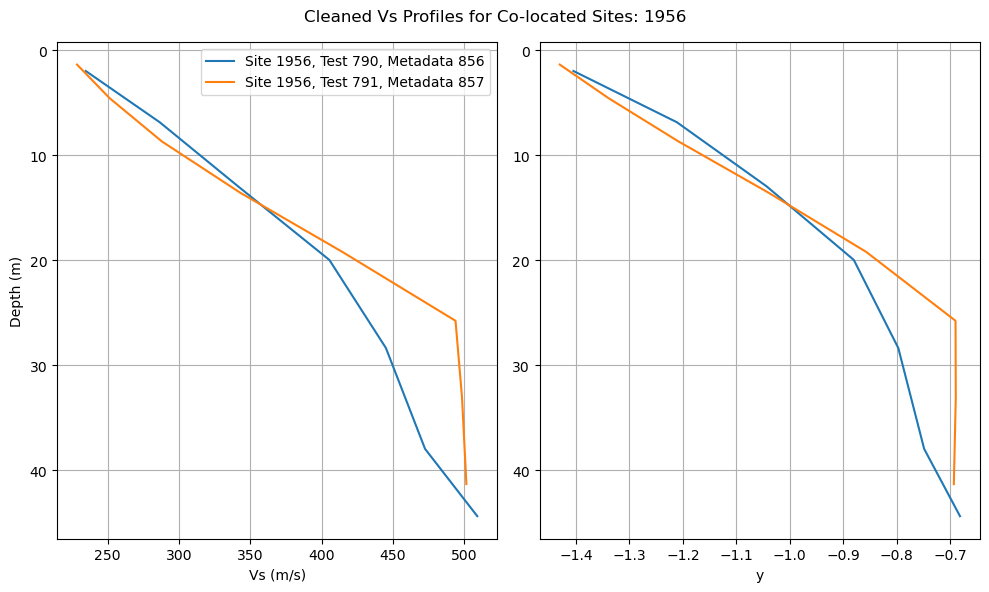

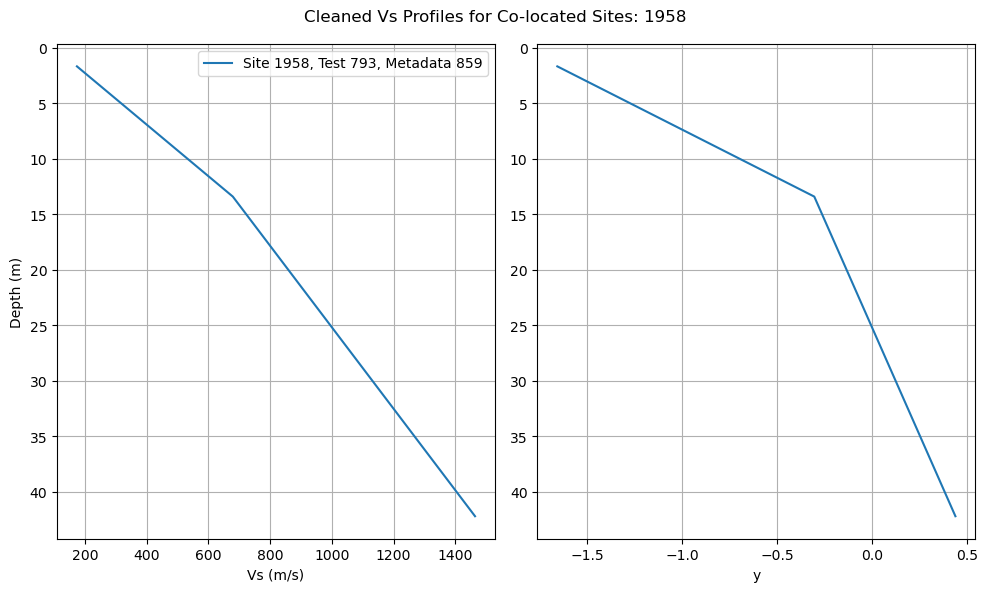

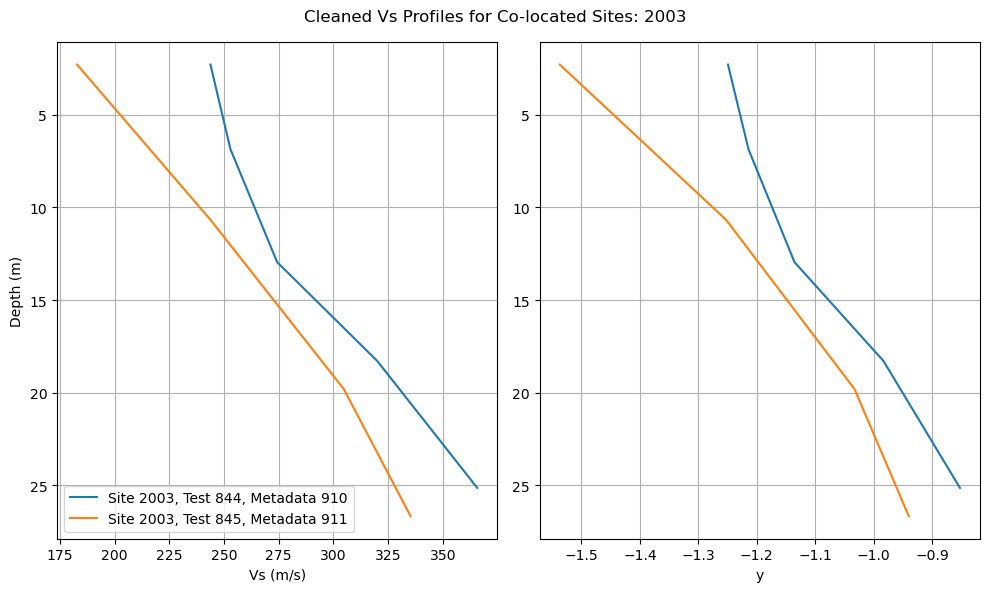

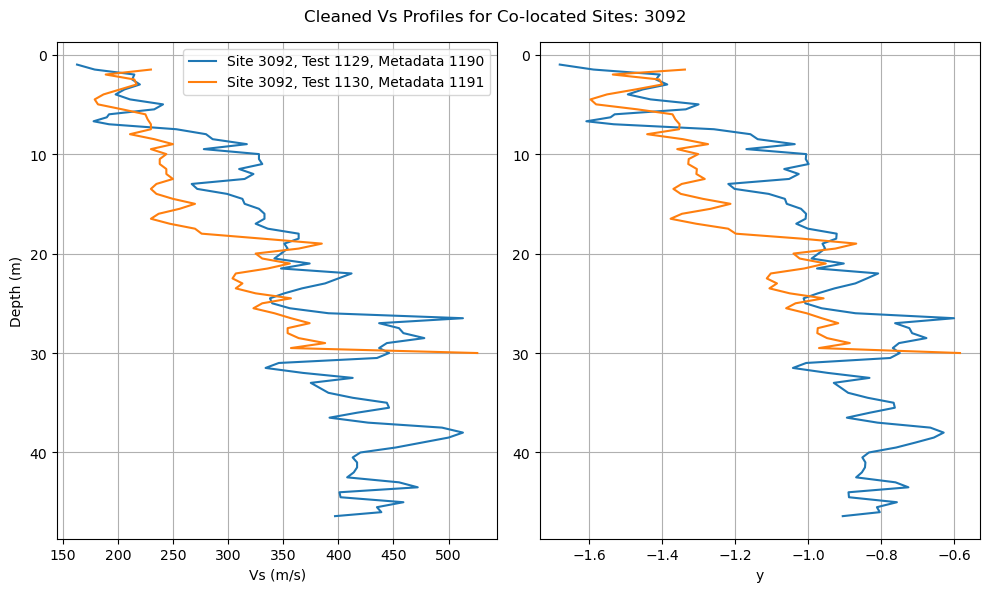

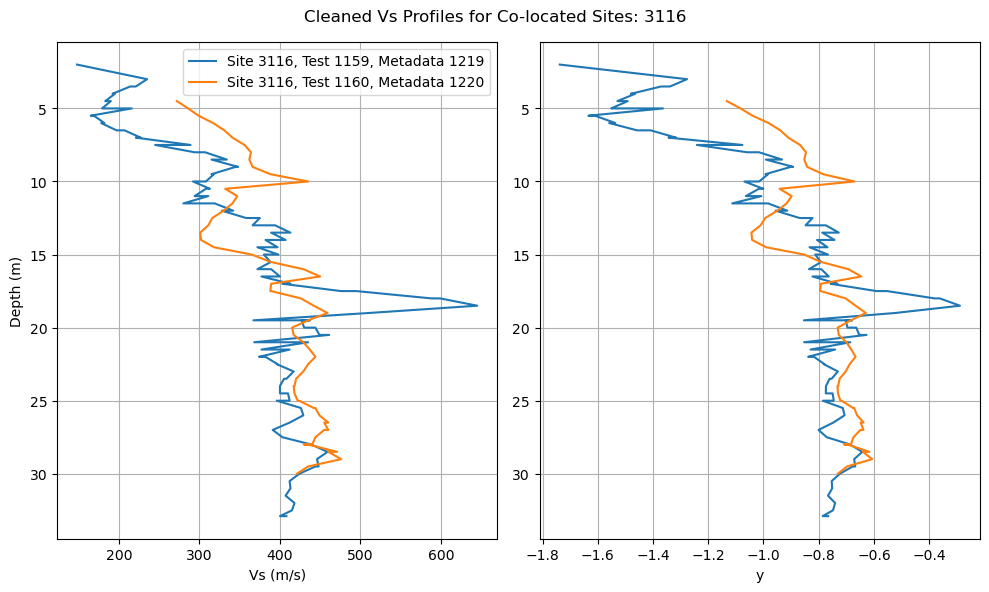

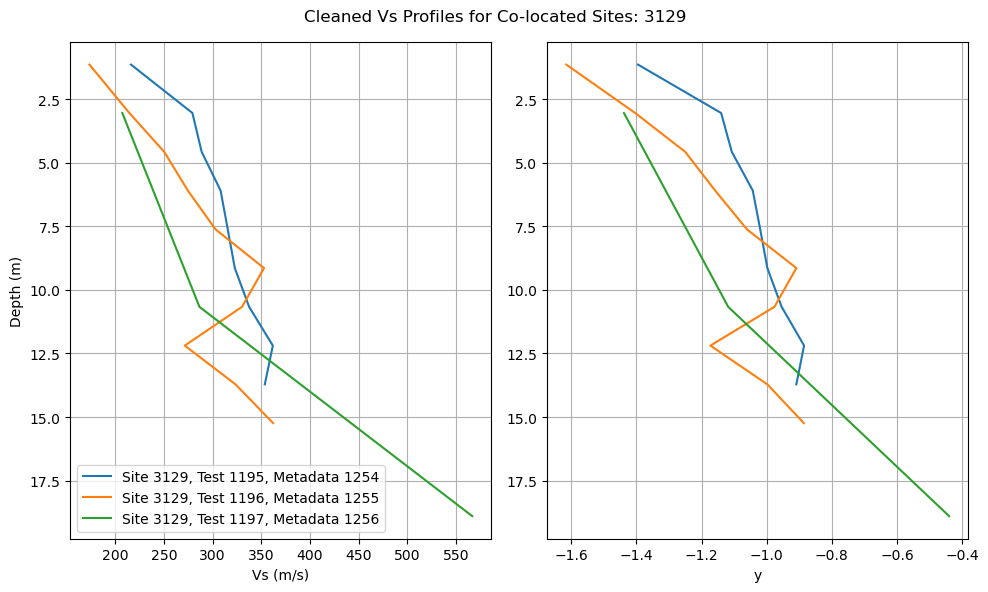

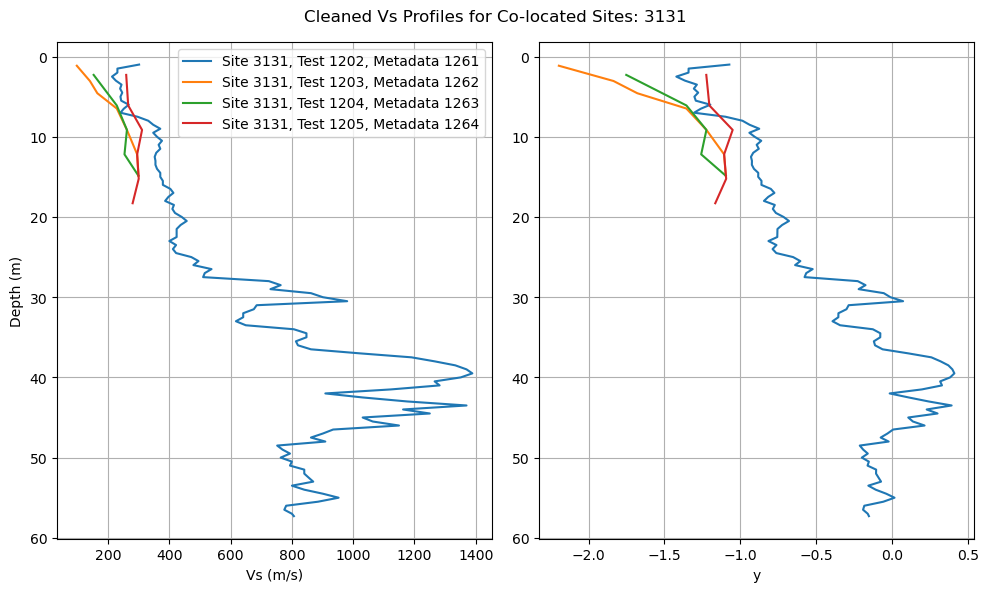

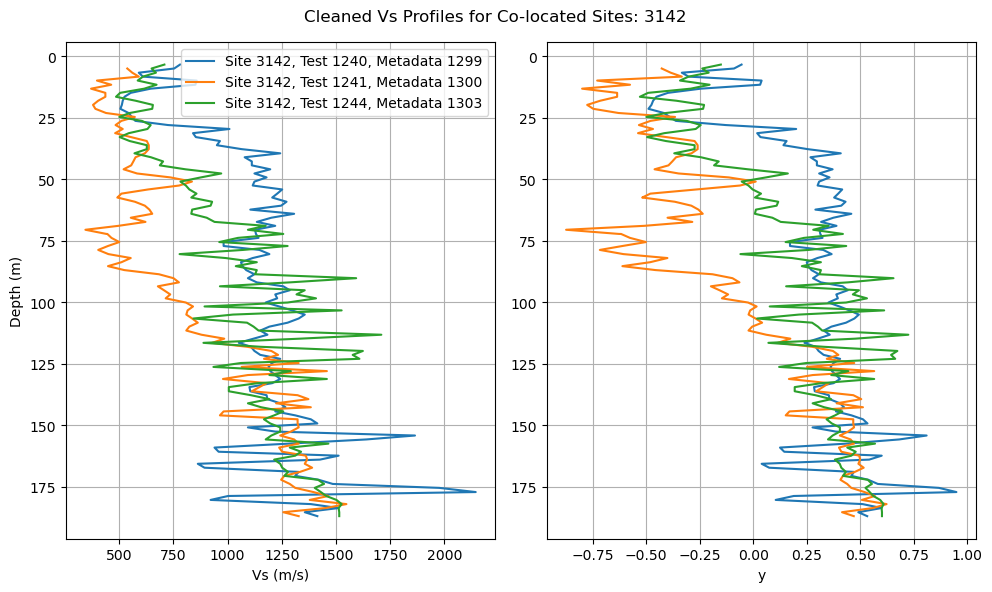

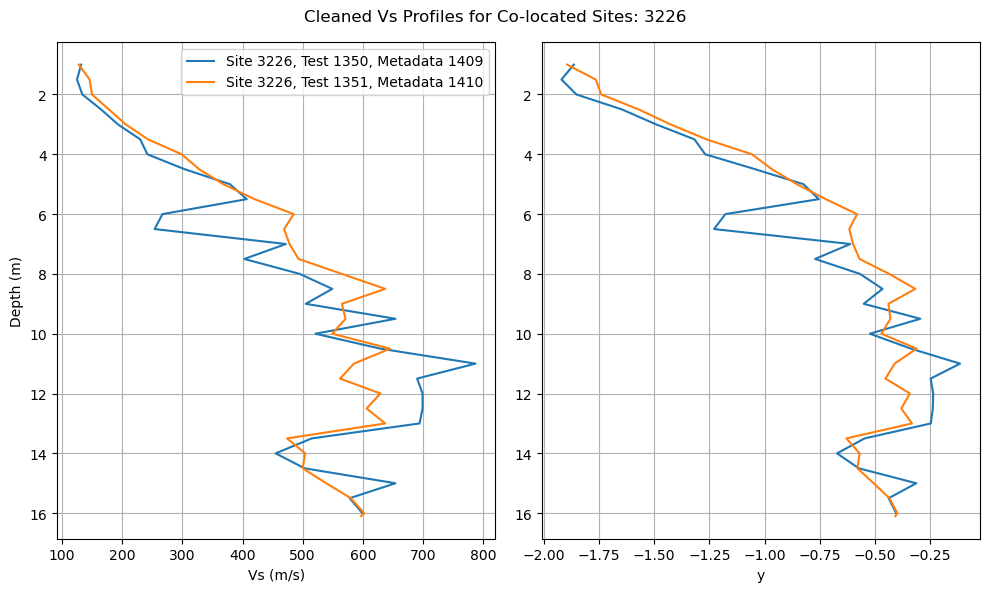

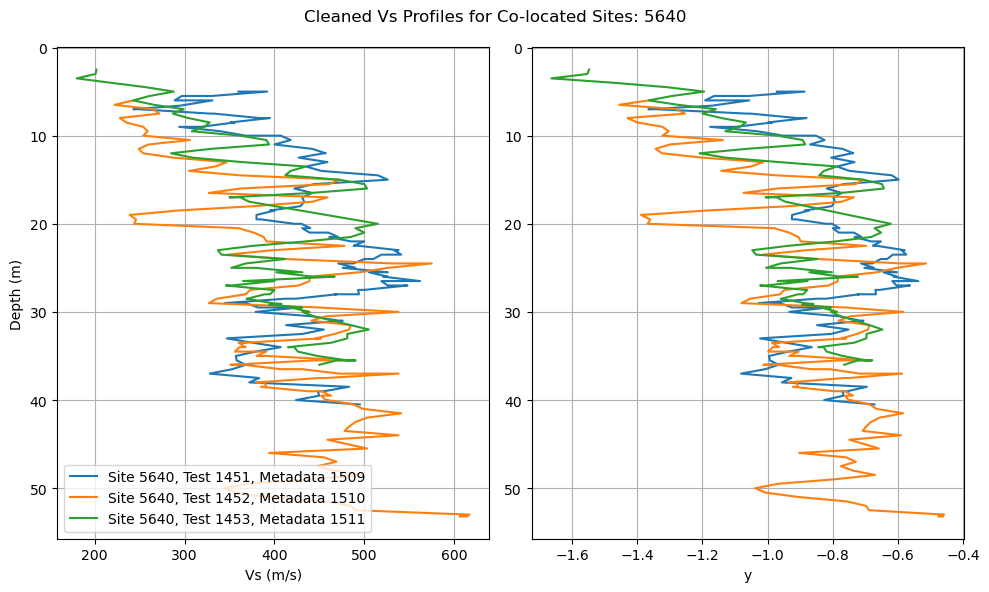

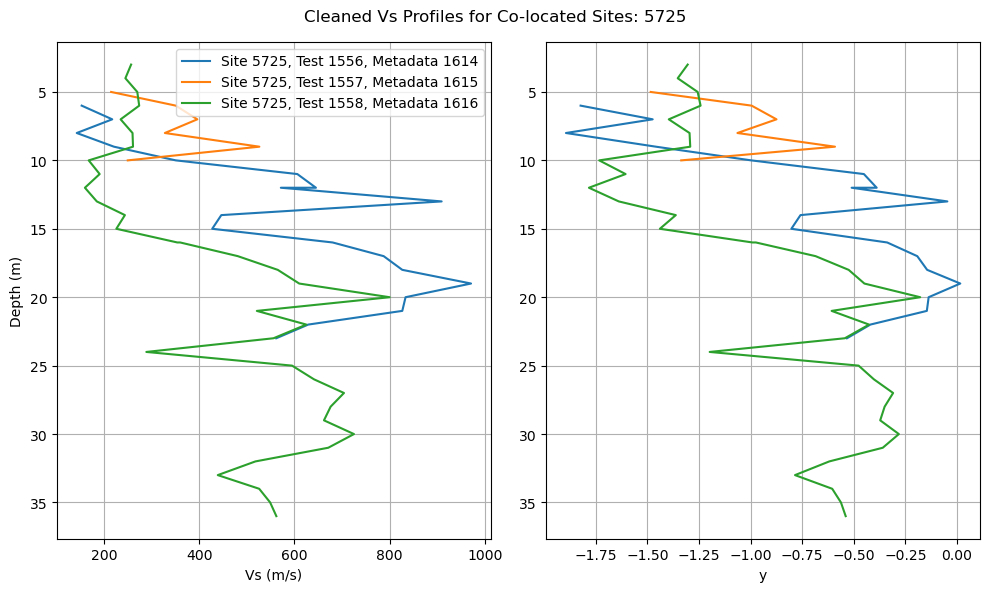

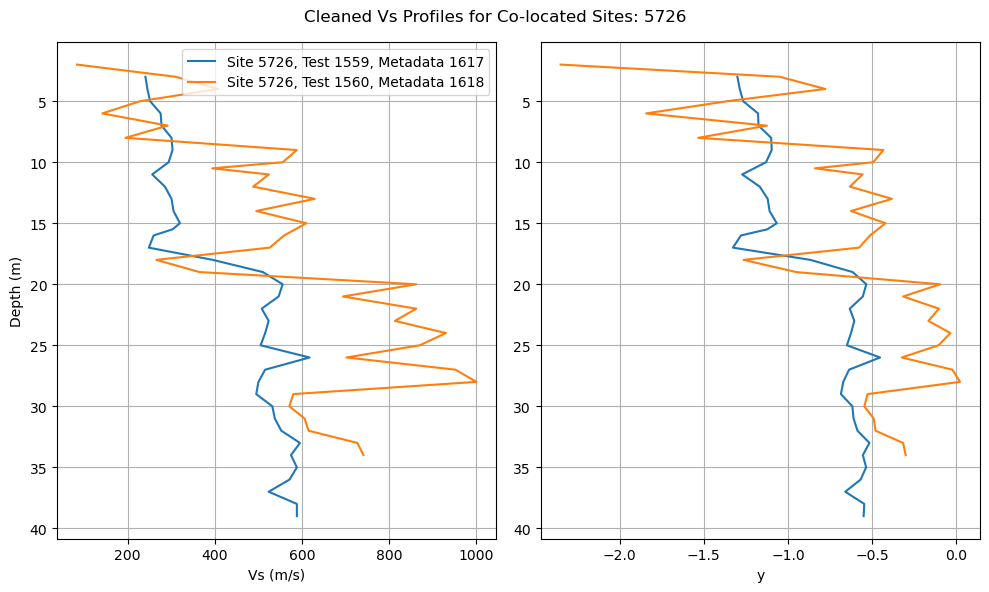

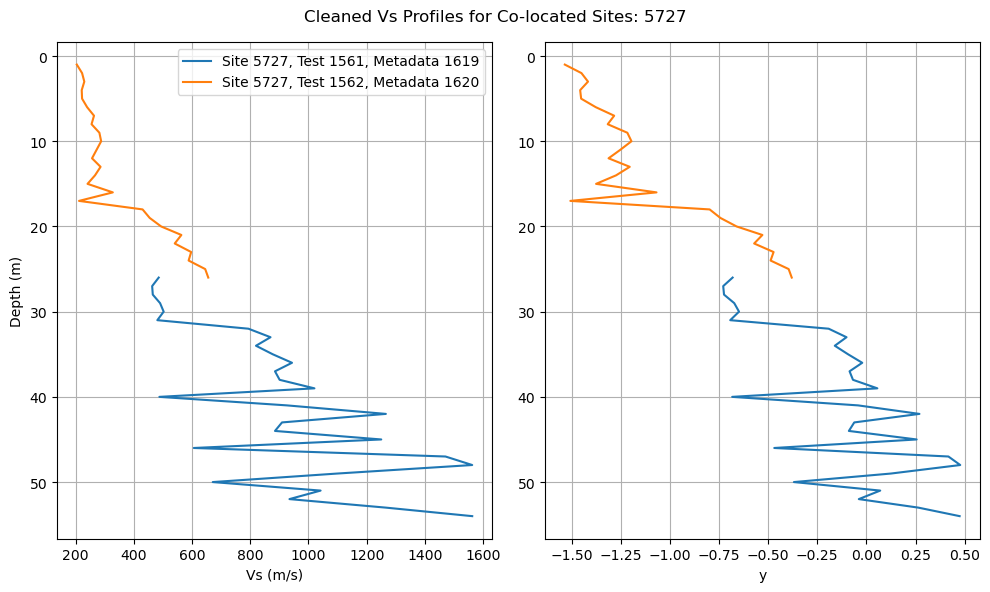

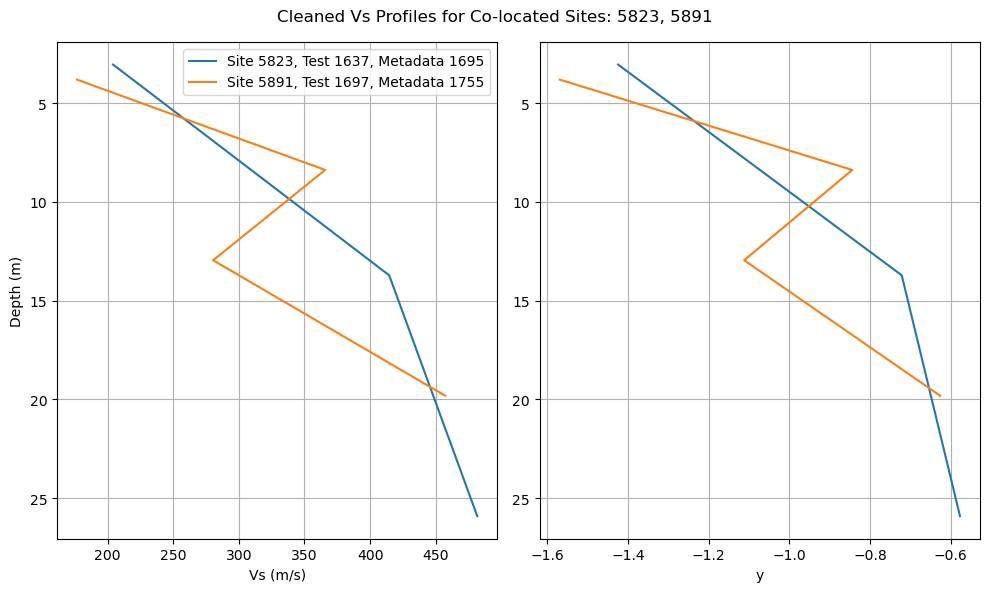

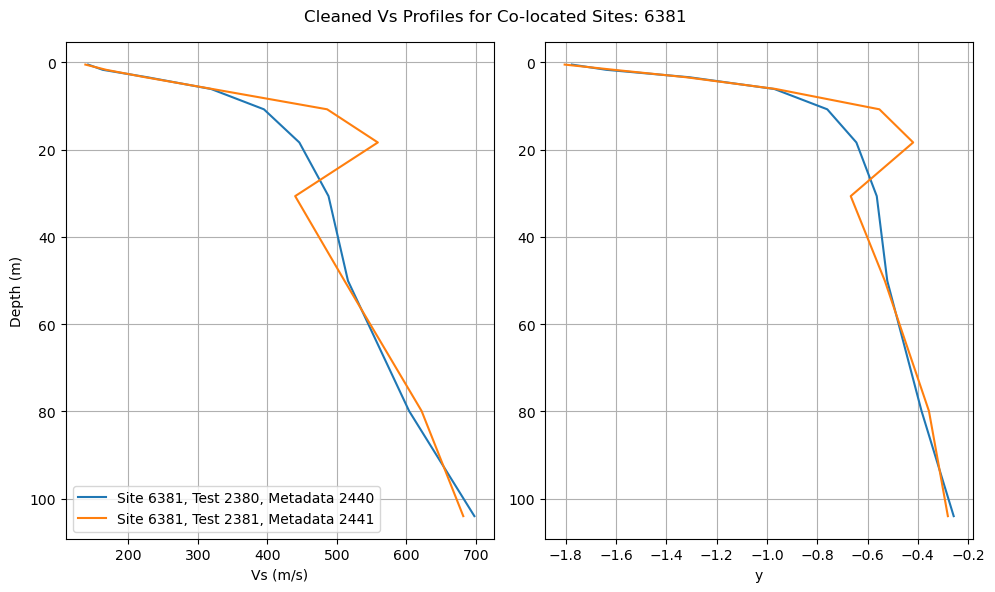

In [18]:
#iterate over groups of colocated sites
for g in list(nx.connected_components(sites_G)):
    #colocated sites
    site_ids = df_sites.loc[list(g), 'site_id'].tolist()

    #identify collocated vel measurements
    df_vs_data_group = df_vs_data[df_vs_data['site_id'].isin(site_ids)]
    if not len(df_vs_data_group): continue
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 6))  # 1 row, 2 columns
    for (mid, sid, tid), prof in df_vs_data_group.groupby(['metadata_id','site_id','test_id']):
        ax1.plot(prof['vs_value'], prof['vs_middle_depth'], label=f'Site {sid}, Test {tid}, Metadata {mid}')
        ax2.plot(prof['diff'], prof['vs_middle_depth'], label=f'Site {sid}, Test {tid}, Metadata {mid}')

    ax1.invert_yaxis()
    ax2.invert_yaxis()
    ax1.set_xlabel('Vs (m/s)')
    ax2.set_xlabel('y')
    ax1.set_ylabel('Depth (m)')
    ax1.legend()
    ax1.grid(True)
    ax2.grid(True)
    
    fig.suptitle(f'Cleaned Vs Profiles for Co-located Sites: {", ".join(map(str, np.unique(site_ids)))}')
    fig.tight_layout()


#### Collocated Tests

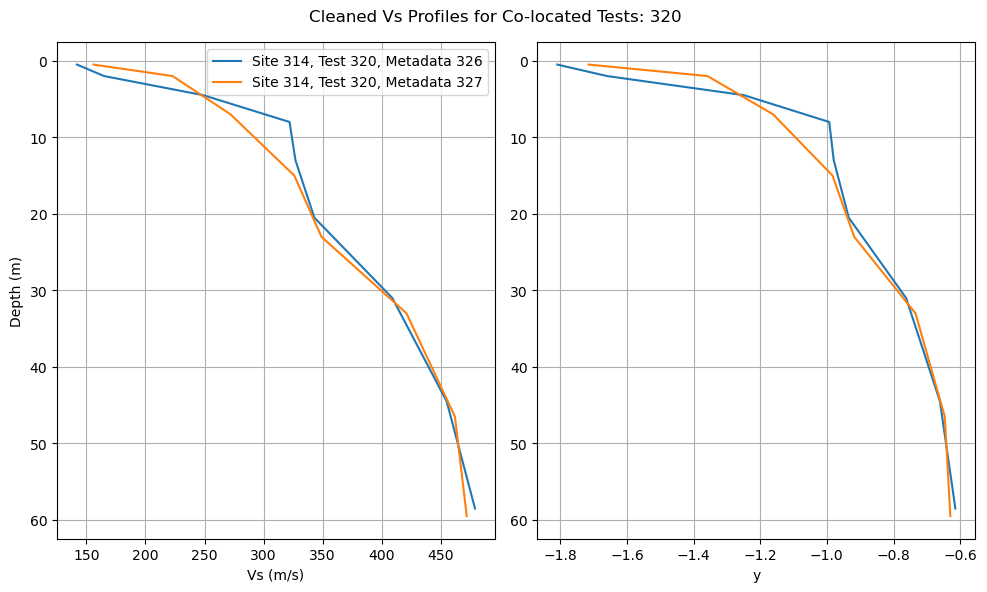

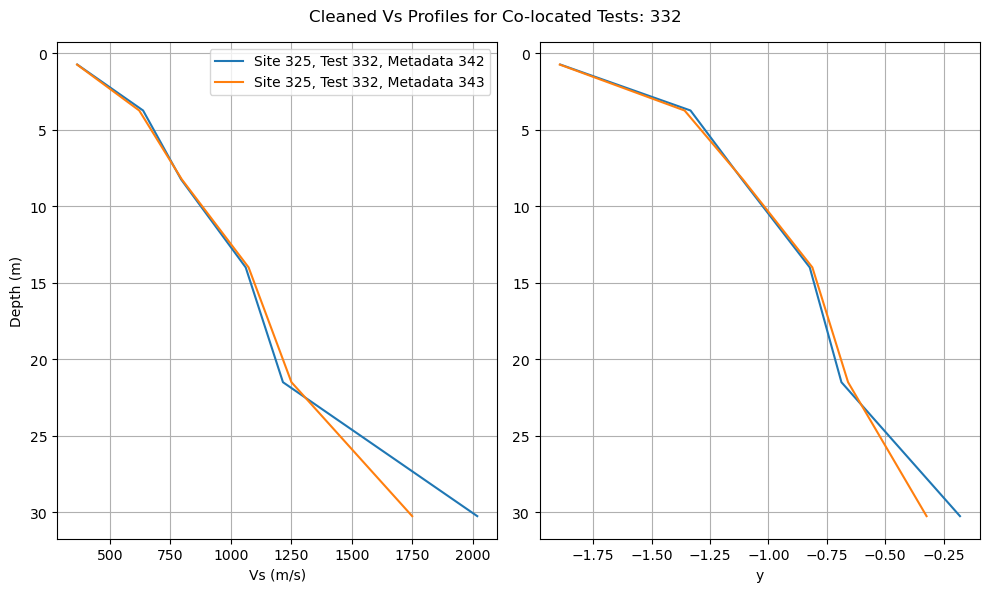

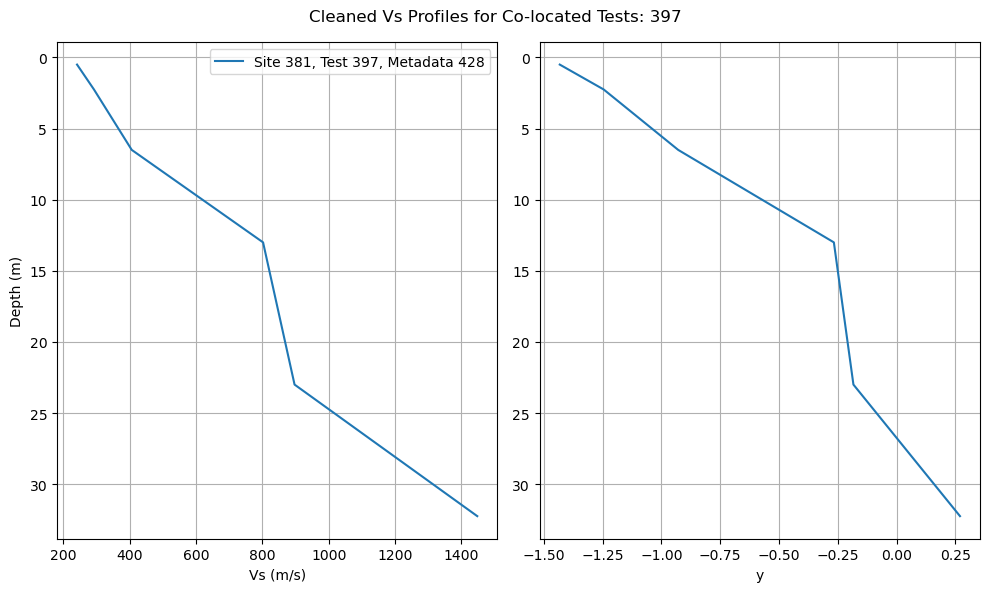

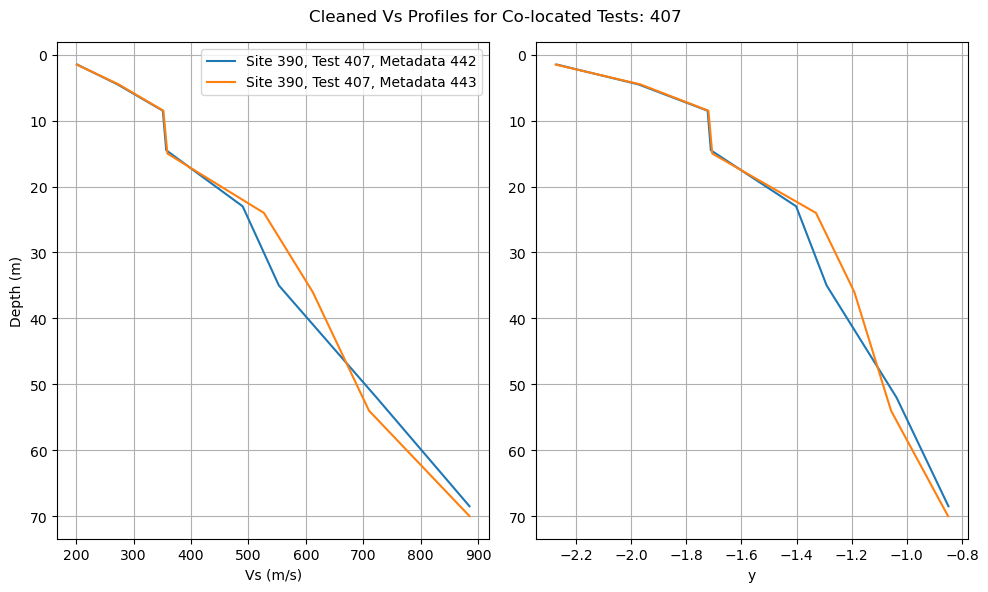

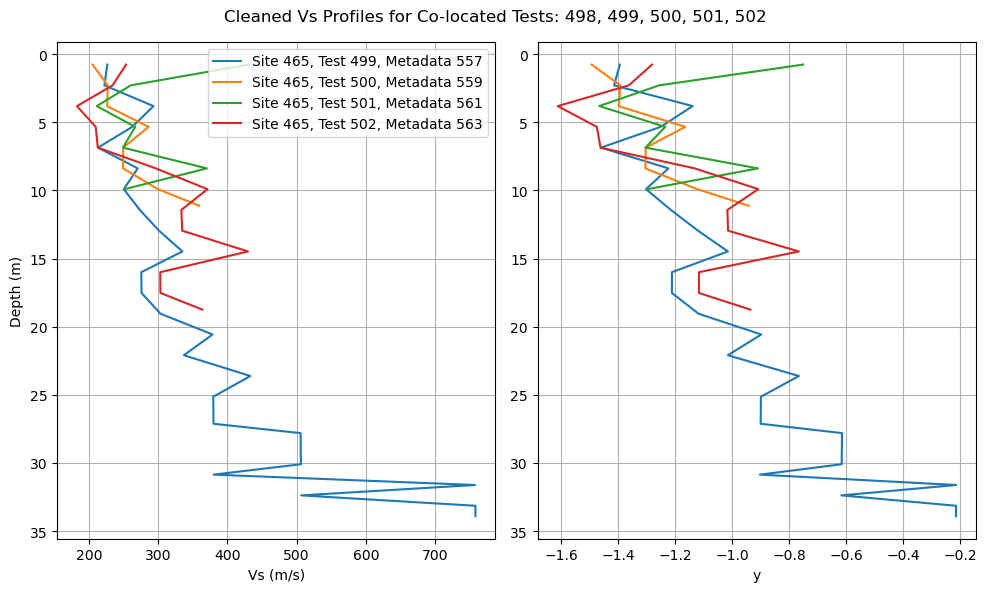

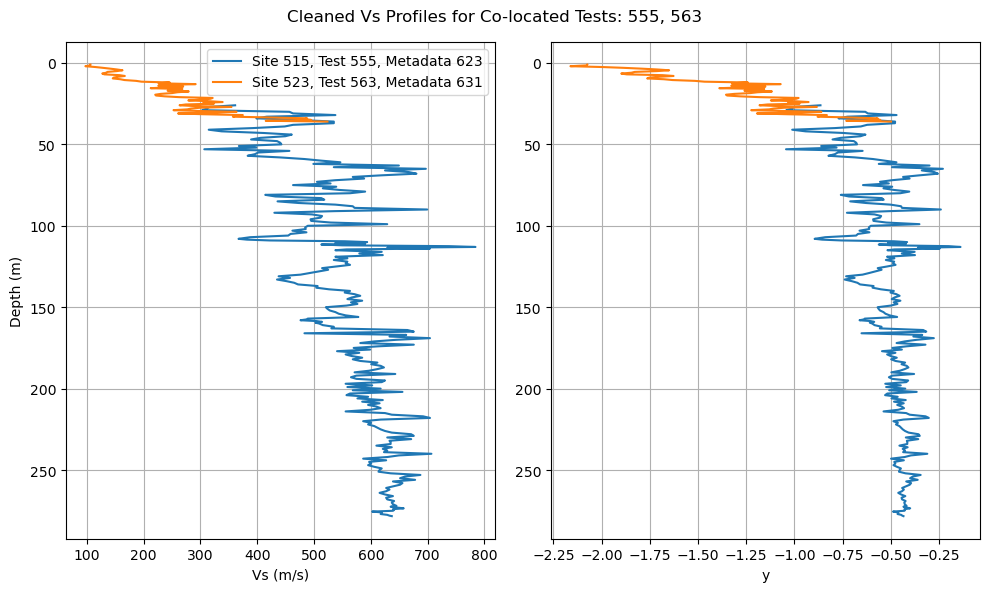

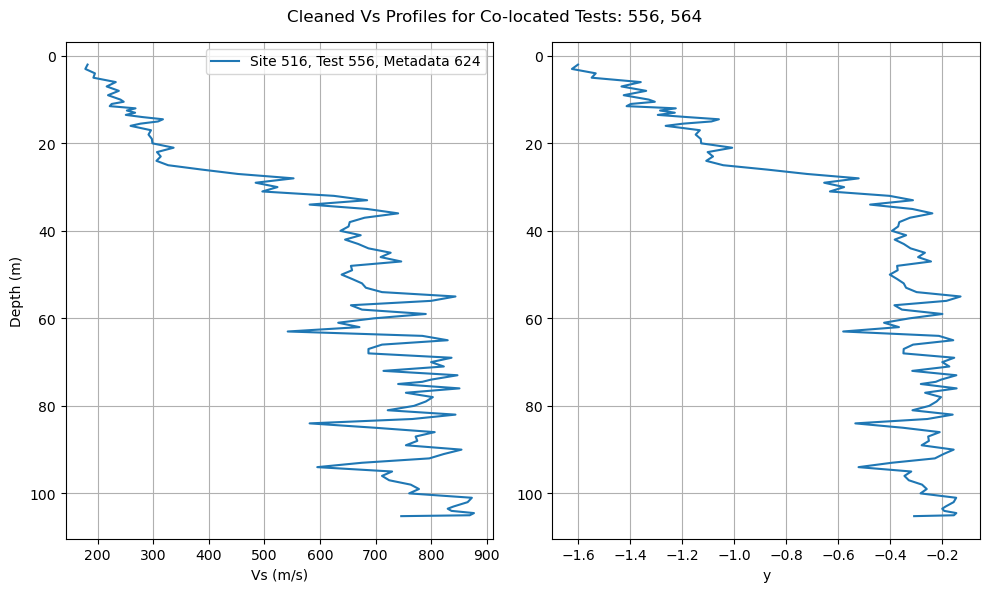

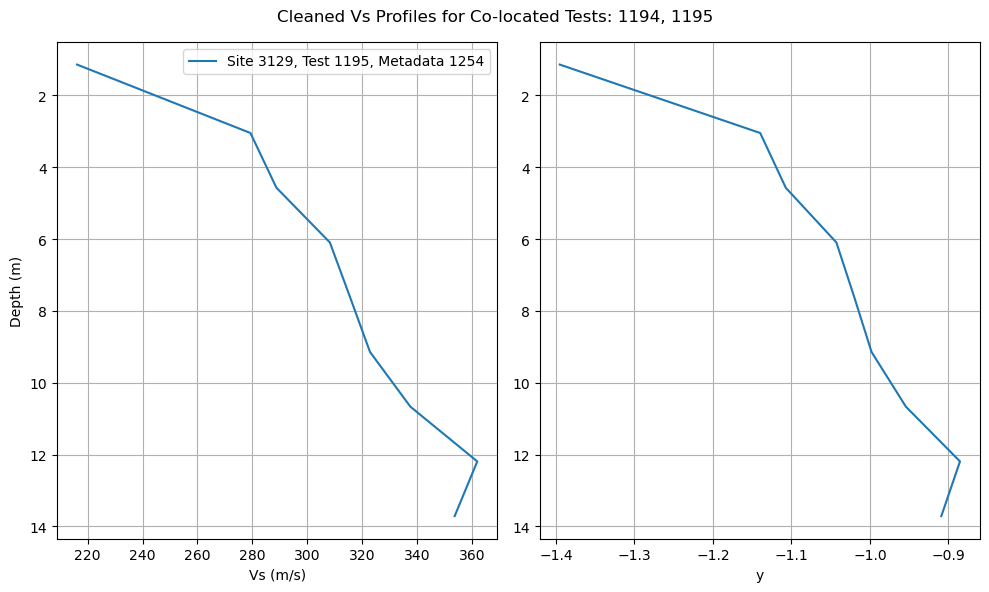

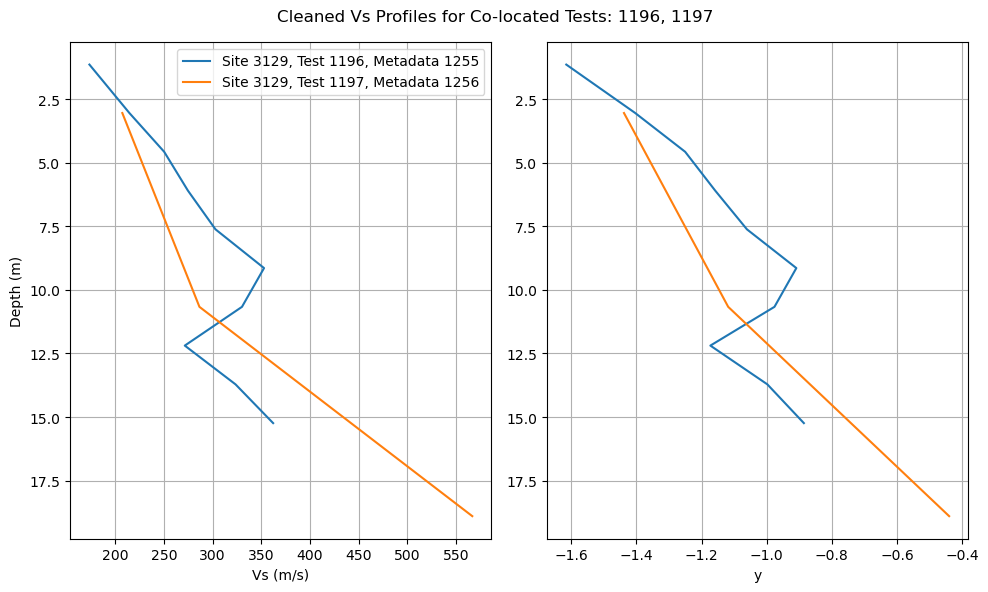

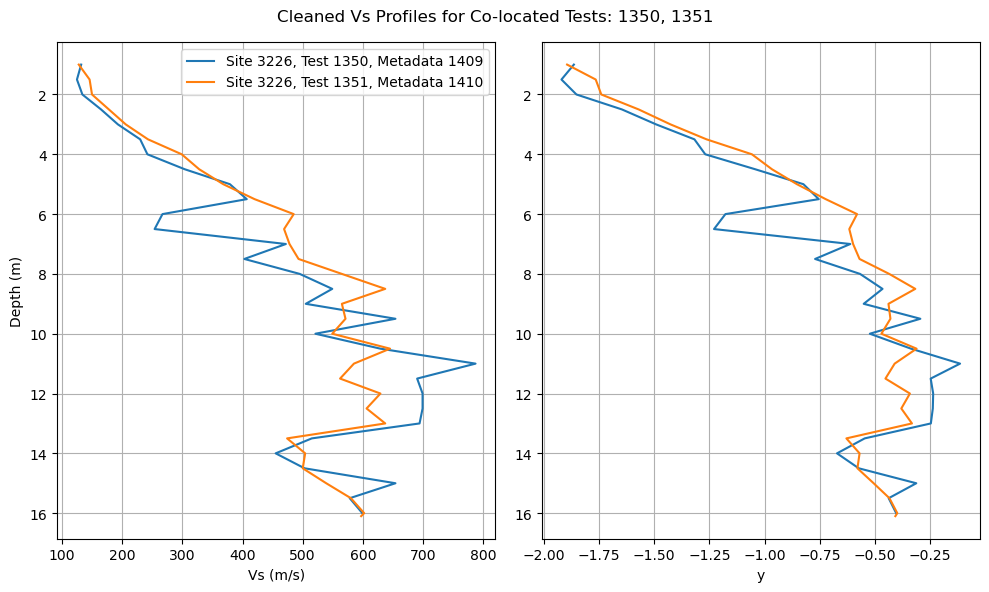

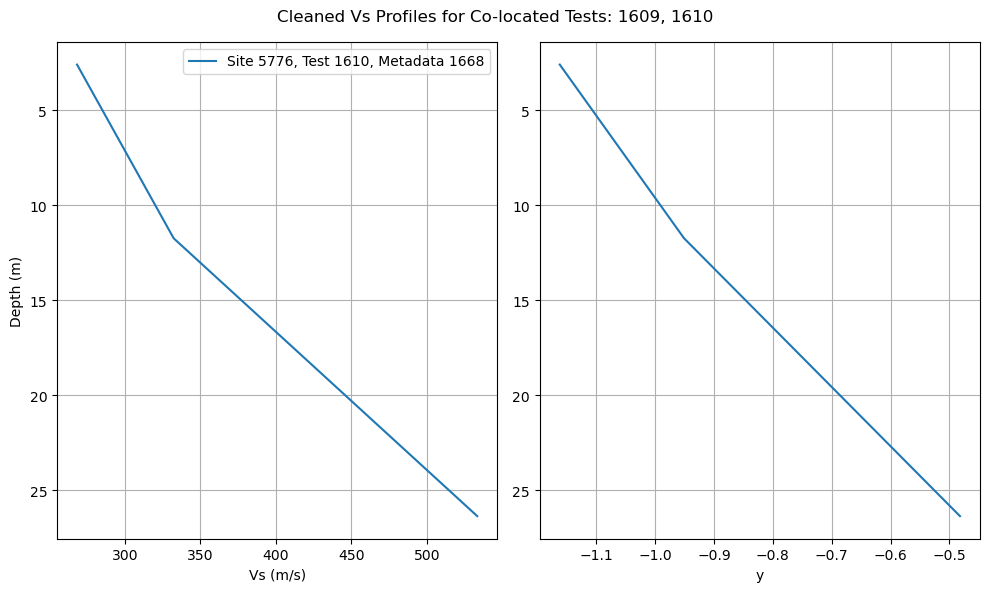

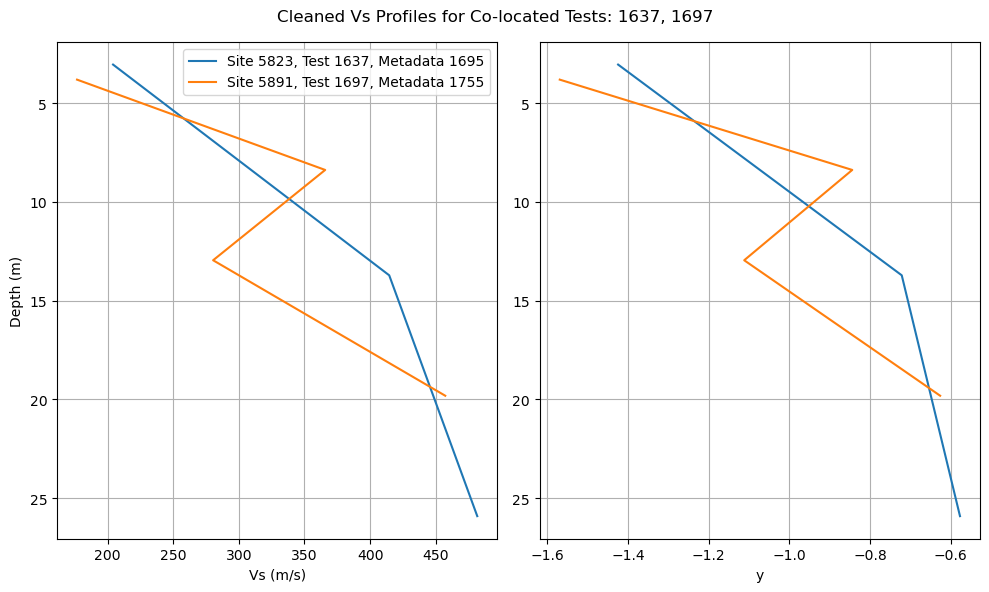

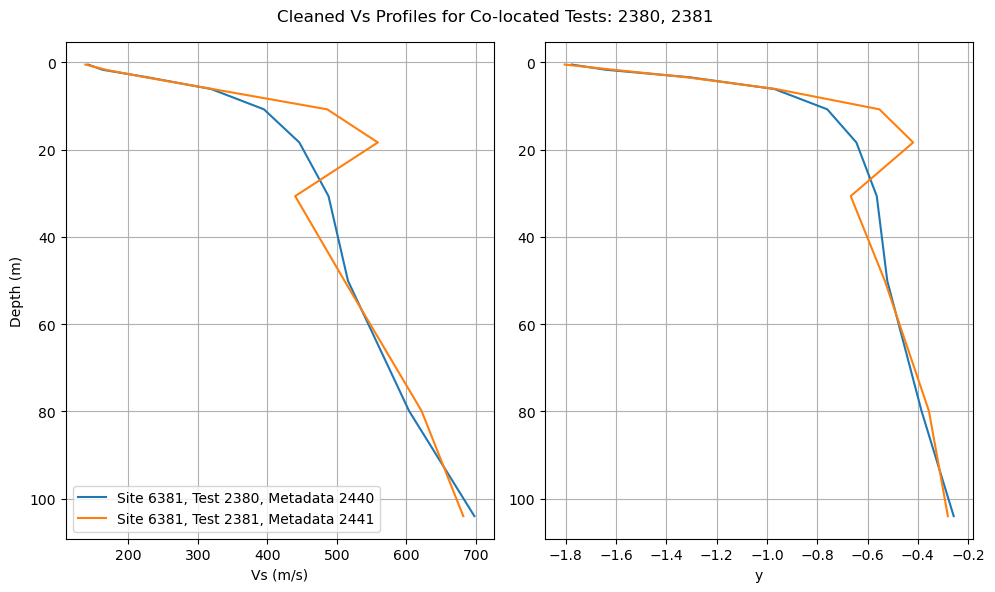

In [19]:
#iterate over groups of colocated tests
for g in list(nx.connected_components(tests_G)):
    #colocated sites
    test_ids = df_sites.loc[list(g), 'test_id'].tolist()

    #group of collocated tests    
    df_vs_data_group = df_vs_data[df_vs_data['test_id'].isin(test_ids)]
    if not len(df_vs_data_group): continue
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 6))  # 1 row, 2 columns
    for (mid, sid, tid), prof in df_vs_data_group.groupby(['metadata_id','site_id','test_id']):
        ax1.plot(prof['vs_value'], prof['vs_middle_depth'], label=f'Site {sid}, Test {tid}, Metadata {mid}')
        ax2.plot(prof['diff'], prof['vs_middle_depth'], label=f'Site {sid}, Test {tid}, Metadata {mid}')

    ax1.invert_yaxis()
    ax2.invert_yaxis()
    ax1.set_xlabel('Vs (m/s)')
    ax2.set_xlabel('y')
    ax1.set_ylabel('Depth (m)')
    ax1.legend()
    ax1.grid(True)
    ax2.grid(True)
    
    fig.suptitle(f'Cleaned Vs Profiles for Co-located Tests: {", ".join(map(str, np.unique(test_ids)))}')
    fig.tight_layout()

### Visualization Currated Dataset

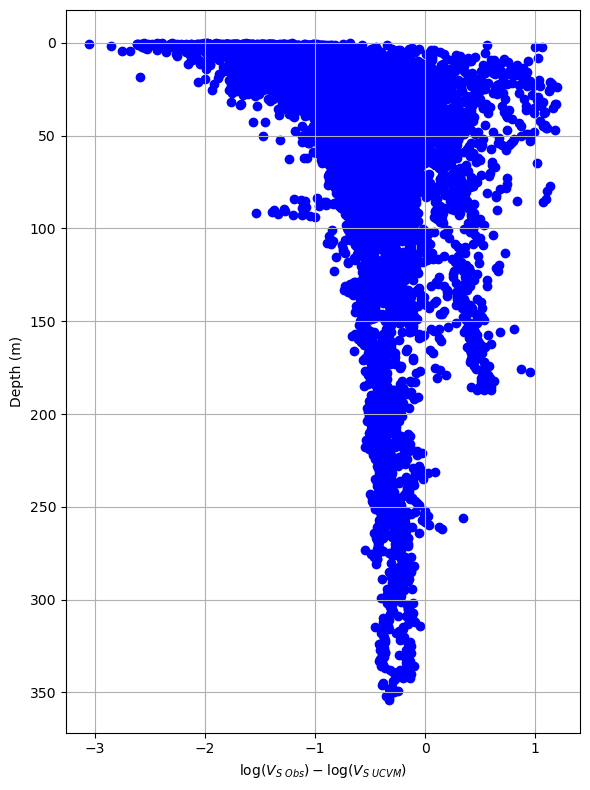

In [20]:
plt.figure(figsize=(6, 8))
plt.scatter(df_vs_data['diff'], df_vs_data['vs_middle_depth'], color='blue')
plt.gca().invert_yaxis()
plt.xlabel(r'$\log(V_{S~Obs}) - \log(V_{S~UCVM})$')
plt.ylabel('Depth (m)')
# plt.legend()
plt.grid(True)
plt.tight_layout()
#plt.savefig(dir_fig+'vs_data_cleaned.svg', format='svg', dpi=300)
#plt.savefig(dir_fig+'vs_data_cleaned.png', format='png', dpi=300)
plt.show()

### Output Vs Data

In [17]:
df_vs_data.to_csv(dir_out+'vs_data_output.txt', index=False,
                  encoding='utf-8',
                  lineterminator='\n')